# Experimentación RAG - EcoMarket (Entrega 2)

Este notebook pone a prueba **todas las alternativas listadas** en:

- `ComponentesSistemaRAG.md` (Fase 1): modelos de embeddings y bases de datos vectoriales.
- `BaseDeConocimiento.md` (Fase 2): estrategias de segmentación (chunking) para texto y datos estructurados.

El objetivo es **justificar con datos** la elección de cada componente.

**Estructura**

0. Configuración
1. Carga de las fuentes de conocimiento
2. Set de evaluación (preguntas etiquetadas)
3. Estrategias de chunking
4. Modelos de embeddings
5. Experimento 1: modelos de embeddings x estrategias de chunking (PDF)
6. Experimento 2: chunking de datos estructurados (por registro vs texto aplanado) y búsqueda híbrida
7. Experimento 3: bases de datos vectoriales (corpus real + prueba de escala)
8. Resumen de resultados

**Métricas de recuperación**

- **Hit@k:** % de preguntas donde al menos un chunk relevante aparece en los *k* primeros resultados.
- **MRR@5:** promedio de `1 / posición` del primer chunk relevante (0 si no aparece en el top 5). Premia que lo relevante quede arriba.
- **Cobertura:** % de preguntas cuya evidencia queda **completa dentro de algún chunk**. Si el chunking parte la evidencia en dos, la pregunta no se puede responder bien.
- **AUC fuera de alcance:** qué tan bien el puntaje máximo de similitud separa preguntas que la base **sí** puede responder de las que **no** (1.0 = separación perfecta, 0.5 = azar). Es clave para que el asistente diga "no tengo esa información".

Un chunk es **relevante** si contiene (tras normalizar mayúsculas, tildes y espacios) la evidencia etiquetada para la pregunta.

**Requisitos:** ver `README.md` de la carpeta `entrega2` (`uv sync`, `docker compose up -d`, keys en `.env`, `ollama serve`). Los modelos de Hugging Face se descargan la primera vez (~5 GB en total, BGE-M3 es el más pesado). Los modelos de Ollama requieren `ollama serve` corriendo.

## 0. Configuración

In [1]:
import gc
import json
import os
import re
import time
import unicodedata
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["ANONYMIZED_TELEMETRY"] = "False"  # telemetria de Chroma

BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = BASE_DIR / "data"
RESULTADOS_DIR = BASE_DIR / "notebooks" / "resultados"
RESULTADOS_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
K = 5  # numero de chunks recuperados por consulta
rng = np.random.default_rng(SEED)

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

# Paleta categorica (orden fijo) y color unico para barras / secuencial
PALETA = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
COLOR_BARRA = "#2a78d6"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
})
print("Datos en:", DATA_DIR)

Datos en: /Users/andresfelipegonzalez/Desktop/maestria/assistant-engine/entrega2/data


### Banderas de ejecución

- Los modelos de Hugging Face se pueden desactivar individualmente (`activo=False`).
- Los modelos de Ollama se activan solo si Ollama responde y el modelo está descargado.
- **OpenAI y Pinecone** leen sus API keys desde `entrega2/.env` (ver `.env.example`).
- **Weaviate** se conecta al contenedor de `docker-compose.yml` (`docker compose up -d` en la carpeta `entrega2`).
- Si alguno no está disponible, se omite y queda registrado en `LIMITACIONES` (se imprime en el resumen final).

In [2]:
# Modelos de embeddings de Hugging Face (sentence-transformers)
MODELOS_HF = {
    "minilm-multilingue": dict(id="sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2", prefijo_doc="", prefijo_query="", params_m=118, activo=True),
    "e5-small":           dict(id="intfloat/multilingual-e5-small", prefijo_doc="passage: ", prefijo_query="query: ", params_m=118, activo=True),
    "e5-base":            dict(id="intfloat/multilingual-e5-base", prefijo_doc="passage: ", prefijo_query="query: ", params_m=278, activo=True),
    "bge-m3":             dict(id="BAAI/bge-m3", prefijo_doc="", prefijo_query="", params_m=568, activo=True),
    "beto-espanol":       dict(id="hiiamsid/sentence_similarity_spanish_es", prefijo_doc="", prefijo_query="", params_m=110, activo=True),
}

# Modelos de embeddings servidos por Ollama
MODELOS_OLLAMA = {
    "nomic-v2-moe": dict(id="nomic-embed-text-v2-moe", prefijo_doc="search_document: ", prefijo_query="search_query: ", params_m=475),
}

# Modelo propietario (solo si hay API key)
MODELOS_OPENAI = {
    "openai-3-small": dict(id="text-embedding-3-small", params_m=None),
}

from dotenv import load_dotenv
load_dotenv(BASE_DIR / ".env")

LIMITACIONES = {}  # componente -> motivo por el que no se pudo evaluar


def weaviate_disponible():
    try:
        import weaviate
        with weaviate.connect_to_local() as cliente:
            return cliente.is_ready()
    except Exception as e:
        LIMITACIONES["weaviate"] = f"Servidor no disponible ({type(e).__name__}). Ejecutar: docker compose up -d"
        return False


EJECUTAR_OPENAI = bool(os.getenv("OPENAI_API_KEY"))
EJECUTAR_PINECONE = bool(os.getenv("PINECONE_API_KEY"))
EJECUTAR_WEAVIATE = weaviate_disponible()
if not EJECUTAR_OPENAI:
    LIMITACIONES["openai-3-small"] = "Falta OPENAI_API_KEY en entrega2/.env"
if not EJECUTAR_PINECONE:
    LIMITACIONES["pinecone"] = "Falta PINECONE_API_KEY en entrega2/.env"

# Prueba de escala de bases vectoriales
TAMANOS_ESCALA = [1_000, 10_000, 100_000]
N_CONSULTAS_ESCALA = 100

# Modelo usado para la segmentacion semantica (fijo para que todos los modelos
# se evaluen sobre los mismos chunks)
MODELO_CHUNKING_SEMANTICO = "minilm-multilingue"


def ollama_disponible():
    """Devuelve el conjunto de modelos descargados en Ollama, o None si no responde."""
    try:
        import ollama
        return {m.model for m in ollama.list().models}
    except Exception as e:
        print("Ollama no disponible:", e)
        return None


modelos_ollama_locales = ollama_disponible()
if modelos_ollama_locales is not None:
    for nombre, cfg in MODELOS_OLLAMA.items():
        cfg["activo"] = any(m == cfg["id"] or m.startswith(cfg["id"] + ":") for m in modelos_ollama_locales)
        if not cfg["activo"]:
            LIMITACIONES[nombre] = f"Modelo no descargado. Ejecutar: ollama pull {cfg['id']}"
else:
    for nombre, cfg in MODELOS_OLLAMA.items():
        cfg["activo"] = False
        LIMITACIONES[nombre] = "Ollama no responde. Ejecutar: ollama serve"

import torch
DEVICE = "mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", DEVICE)
print("HF activos:", [n for n, c in MODELOS_HF.items() if c["activo"]])
print("Ollama activos:", [n for n, c in MODELOS_OLLAMA.items() if c["activo"]])
print("OpenAI:", EJECUTAR_OPENAI, "| Weaviate:", EJECUTAR_WEAVIATE, "| Pinecone:", EJECUTAR_PINECONE)
for componente, motivo in LIMITACIONES.items():
    print(f"  [omitido] {componente}: {motivo}")

Dispositivo: mps
HF activos: ['minilm-multilingue', 'e5-small', 'e5-base', 'bge-m3', 'beto-espanol']
Ollama activos: ['nomic-v2-moe']
OpenAI: True | Weaviate: True | Pinecone: True


## 1. Carga de las fuentes de conocimiento

| Fuente | Archivo | Loader |
|---|---|---|
| Política | `politica_devoluciones.pdf` | `pymupdf` (bloques = párrafos) |
| Catálogo | `catalogo_productos.pdf` | `pymupdf` (lista de productos por categoría) |
| Inventario | `inventario_productos.xlsx` | `pandas` |
| FAQ | `preguntas_frecuentes.json` | `json` |
| Pedidos | `pedidos.xlsx` | `pandas` |

In [3]:
archivos = ["politica_devoluciones.pdf", "catalogo_productos.pdf", "inventario_productos.xlsx",
            "preguntas_frecuentes.json", "pedidos.xlsx"]
faltantes = [a for a in archivos if not (DATA_DIR / a).exists()]
assert not faltantes, f"Faltan archivos en {DATA_DIR}: {faltantes}"


def normalizar(texto: str) -> str:
    """Minusculas, sin tildes y con espacios colapsados (para comparar evidencias)."""
    texto = unicodedata.normalize("NFKD", texto.lower())
    texto = "".join(c for c in texto if not unicodedata.combining(c))
    return " ".join(texto.split())


PATRON_TITULO = re.compile(r"^\d+\.\s+\S")


def es_titulo(texto: str) -> bool:
    return bool(PATRON_TITULO.match(texto)) and len(texto) < 80 and not texto.endswith(".")

In [4]:
import pymupdf


def cargar_politica(ruta: Path) -> list[dict]:
    """Extrae los parrafos del PDF y los asocia a su seccion.

    pymupdf devuelve bloques de texto que corresponden a parrafos. Un parrafo
    que cruza de pagina queda en dos bloques: se unen si el primero no termina
    en puntuacion y el siguiente empieza en minuscula.
    """
    bloques = []
    with pymupdf.open(ruta) as doc:
        for num_pagina, pagina in enumerate(doc, start=1):
            for b in pagina.get_text("blocks"):
                texto = " ".join(b[4].split())
                if not texto:
                    continue
                if bloques and not bloques[-1]["texto"].endswith((".", ":")) and texto[0].islower():
                    bloques[-1]["texto"] += " " + texto
                else:
                    bloques.append({"texto": texto, "pagina": num_pagina})
    seccion = "Encabezado"
    parrafos = []
    for b in bloques:
        if es_titulo(b["texto"]):
            seccion = b["texto"]
            parrafos.append({**b, "seccion": seccion, "es_titulo": True})
        else:
            parrafos.append({**b, "seccion": seccion, "es_titulo": False})
    return parrafos


parrafos_politica = cargar_politica(DATA_DIR / "politica_devoluciones.pdf")
texto_politica = "\n\n".join(p["texto"] for p in parrafos_politica)
print(f"Parrafos: {len(parrafos_politica)} | Secciones: {sum(p['es_titulo'] for p in parrafos_politica)} | Caracteres: {len(texto_politica):,}")
print(texto_politica[:600])

Parrafos: 51 | Secciones: 14 | Caracteres: 9,469
EcoMarket - Política de Devoluciones, Reembolsos, Envíos y Garantías

Versión 3.2 - Vigente desde el 1 de agosto de 2026

1. Objeto y alcance

Esta política establece las condiciones bajo las cuales los clientes de EcoMarket pueden devolver, cambiar o solicitar el reembolso de los productos comprados a través de nuestra tienda en línea, nuestra aplicación móvil y nuestro canal de WhatsApp. Aplica a todas las compras realizadas en Colombia y entregadas en el territorio nacional.

Las compras realizadas en ferias, tiendas aliadas o puntos físicos de terceros se rigen por las políticas de cada es


<frozen importlib._bootstrap>:241: DeprecationWarning: builtin type SwigPyPacked has no __module__ attribute
<frozen importlib._bootstrap>:241: DeprecationWarning: builtin type SwigPyObject has no __module__ attribute
<frozen importlib._bootstrap>:241: DeprecationWarning: builtin type swigvarlink has no __module__ attribute


In [5]:
# Catalogo: lista de productos por categoria (texto tipo lista, no parrafos)
with pymupdf.open(DATA_DIR / "catalogo_productos.pdf") as doc:
    texto_catalogo = "\n".join(" ".join(b[4].split()) for pagina in doc for b in pagina.get_text("blocks"))
print(f"Catalogo: {len(texto_catalogo):,} caracteres\n")
print(texto_catalogo)

Catalogo: 1,216 caracteres

Catálogo de productos que vende EcoMarket
Todos los productos se venden en la tienda en línea de EcoMarket, agrupados por categoría.
Menaje: Botella reutilizable de acero, Bolsa de tela para mercado, Set de contenedores de vidrio, Pitillos de acero inoxidable x4, Termo de bambu 500ml.
Cocina reutilizable: Envoltura de cera de abejas x3, Cepillo para platos de fique.
Higiene personal: Cepillo de dientes de bambu, Jabon en barra natural, Desodorante natural en barra, Copa menstrual de silicona, Toallas desmaquillantes de tela x10.
Alimentos: Cafe organico en grano 500g, Miel organica 350g, Panela organica 1kg, Granola artesanal sin azucar 400g.
Aseo del hogar: Detergente biodegradable 1L, Recarga de detergente a granel.
Papelería: Cuaderno de papel reciclado, Agenda 2027 de papel de piedra.
Electrodomésticos: Compostera electrica de cocina, Lampara solar de jardin.
Jardinería: Kit de semillas de huerta, Maceta de fibra de coco.
Plantas vivas: Orquidea en macet

In [6]:
df_inventario = pd.read_excel(DATA_DIR / "inventario_productos.xlsx")
df_pedidos = pd.read_excel(DATA_DIR / "pedidos.xlsx").fillna("")
faq = json.loads((DATA_DIR / "preguntas_frecuentes.json").read_text("utf-8"))

print("Inventario:", df_inventario.shape, "| Pedidos:", df_pedidos.shape, "| FAQ:", len(faq))
display(df_inventario.head(3))
display(df_pedidos.head(3))
print(json.dumps(faq[0], ensure_ascii=False, indent=2))

Inventario: (30, 9) | Pedidos: (30, 10) | FAQ: 30


,sku,producto,categoria,descripcion,precio_cop,stock_disponible,es_devolvible,dias_para_devolucion,motivo_politica
0,EM-001,Botella reutilizable de acero,menaje,"Botella térmica de acero inoxidable de 750 ml, mantiene bebidas frías 24 horas y calientes 12 horas.",69900,120,si,30,Producto no perecedero y no de higiene personal
1,EM-002,Cepillo de dientes de bambu,higiene personal,Cepillo con mango de bambú biodegradable y cerdas de nylon libre de BPA.,12900,340,no,0,"Producto de higiene personal, no puede reingresar a inventario por salud"
2,EM-003,Cafe organico en grano 500g,alimento perecedero,"Café de origen Huila, tostión media, cultivado sin agroquímicos.",38900,85,no,0,"Producto perecedero, no se acepta devolucion una vez entregado"


,tracking_number,cliente,ciudad,fecha_compra,productos,estado,fecha_estimada_entrega,transportadora,observaciones,enlace_rastreo
0,ECO-1001,Laura Martinez,Bogota,2026-09-05,Botella reutilizable de acero; Bolsa de tela para mercado,Entregado,2026-09-10,Servientrega,Entregado en porteria,https://ecomarket.example.com/rastreo/ECO-1001
1,ECO-1002,Carlos Ramirez,Medellin,2026-09-19,Cafe organico en grano 500g,En camino,2026-09-24,Coordinadora,,https://ecomarket.example.com/rastreo/ECO-1002
2,ECO-1003,Diana Lopez,Pasto,2026-09-18,Set de contenedores de vidrio,Retrasado,2026-09-27,Interrapidisimo,Retraso por cierre de la via Panamericana debido a derrumbes,https://ecomarket.example.com/rastreo/ECO-1003


{
  "id": "FAQ-01",
  "categoria": "pagos",
  "pregunta": "¿Qué medios de pago aceptan?",
  "respuesta": "Aceptamos tarjetas de crédito y débito Visa, Mastercard y American Express, PSE, Nequi, Daviplata y pago contra entrega en efectivo en ciudades principales."
}


### Serialización de registros estructurados

Cada registro se convierte en un texto en lenguaje natural `campo: valor`, que es lo que entiende un modelo de embeddings.

**Pedidos:** siguiendo las reglas de privacidad de la Entrega 1, **no** se indexan el nombre del cliente ni los productos del pedido.

In [7]:
def formatear_precio(valor) -> str:
    return f"{int(valor):,}".replace(",", ".")


def texto_producto(r) -> str:
    stock = f"{r.stock_disponible} unidades disponibles" if r.stock_disponible > 0 else "AGOTADO, sin unidades disponibles"
    devolucion = (f"Sí admite devolución, plazo de {r.dias_para_devolucion} días" if r.es_devolvible == "si"
                  else "No admite devolución")
    return (f"Producto: {r.producto} (SKU {r.sku}). Categoría: {r.categoria}. {r.descripcion} "
            f"Precio: {formatear_precio(r.precio_cop)} pesos. Stock: {stock}. "
            f"Devolución: {devolucion}. Motivo: {r.motivo_politica}.")


def texto_pedido(r) -> str:
    obs = f" Observaciones: {r.observaciones}." if r.observaciones else ""
    return (f"Pedido número de seguimiento {r.tracking_number}. Estado: {r.estado}. Ciudad de destino: {r.ciudad}. "
            f"Fecha de compra: {r.fecha_compra}. Fecha estimada de entrega: {r.fecha_estimada_entrega}. "
            f"Transportadora: {r.transportadora}. Enlace de rastreo: {r.enlace_rastreo}.{obs}")


def texto_faq(f) -> str:
    return f"Pregunta frecuente ({f['categoria']}): {f['pregunta']} Respuesta: {f['respuesta']}"


registros_estructurados = (
    [{"texto": texto_producto(r), "fuente": "inventario", "registro_id": r.sku} for r in df_inventario.itertuples()]
    + [{"texto": texto_faq(f), "fuente": "faq", "registro_id": f["id"]} for f in faq]
    + [{"texto": texto_pedido(r), "fuente": "pedidos", "registro_id": r.tracking_number} for r in df_pedidos.itertuples()]
)
print(len(registros_estructurados), "registros")
for fuente in ["inventario", "faq", "pedidos"]:
    print(f"\n[{fuente}]", next(r["texto"] for r in registros_estructurados if r["fuente"] == fuente))

90 registros

[inventario] Producto: Botella reutilizable de acero (SKU EM-001). Categoría: menaje. Botella térmica de acero inoxidable de 750 ml, mantiene bebidas frías 24 horas y calientes 12 horas. Precio: 69.900 pesos. Stock: 120 unidades disponibles. Devolución: Sí admite devolución, plazo de 30 días. Motivo: Producto no perecedero y no de higiene personal.

[faq] Pregunta frecuente (pagos): ¿Qué medios de pago aceptan? Respuesta: Aceptamos tarjetas de crédito y débito Visa, Mastercard y American Express, PSE, Nequi, Daviplata y pago contra entrega en efectivo en ciudades principales.

[pedidos] Pedido número de seguimiento ECO-1001. Estado: Entregado. Ciudad de destino: Bogota. Fecha de compra: 2026-09-05. Fecha estimada de entrega: 2026-09-10. Transportadora: Servientrega. Enlace de rastreo: https://ecomarket.example.com/rastreo/ECO-1001. Observaciones: Entregado en porteria.


## 2. Set de evaluación

Preguntas redactadas como las escribiría un cliente, etiquetadas con:

- `fuente`: dónde está la respuesta (o `fuera_de_alcance`).
- `evidencia`: uno o más fragmentos de texto que **deben** estar en el chunk recuperado (cualquiera de ellos sirve). Para inventario se usa el SKU y para pedidos el número de seguimiento.
- `variante`: `formal`, `coloquial`, `sin_tildes` o `con_errores`, para medir la robustez en español.

Las preguntas **fuera de alcance** no tienen respuesta en la base; sirven para medir si el puntaje de similitud permite detectar cuándo el asistente debe decir que no tiene información.

In [8]:
P = lambda pregunta, fuente, evidencia, variante: dict(
    pregunta=pregunta, fuente=fuente,
    evidencia=[evidencia] if isinstance(evidencia, str) else evidencia, variante=variante)

PREGUNTAS = [
    # --- Politica (PDF) ---
    P("¿Cuántos días tengo para devolver un producto?", "politica", "contados a partir de la fecha de entrega", "formal"),
    P("cuanto tiempo tengo pa devolver un cuaderno", "politica", ["plazo reducido de 15 días", "EM-009"], "coloquial"),
    P("¿Cuál es el plazo para devolver ropa de segunda mano?", "politica", ["plazo especial de 10 días calendario", "EM-019"], "formal"),
    P("Si compro un regalo en diciembre, ¿hasta cuándo lo puedo devolver?", "politica", "hasta el 15 de enero del año siguiente", "formal"),
    P("Boté la caja original, ¿todavía puedo devolver el producto?", "politica", "descuento del 10% sobre el valor a reembolsar", "coloquial"),
    P("¿Qué pasa si devuelvo algo que ya usé?", "politica", "serán rechazados y reenviados al cliente", "formal"),
    P("¿Puedo devolver una tarjeta de regalo?", "politica", ["tarjetas de regalo, productos comprados en la sección de liquidación", "EM-027"], "formal"),
    P("¿Cómo inicio una devolución?", "politica", "hacer clic en Solicitar devolución", "formal"),
    P("que es el codigo rma y cuanto dura", "politica", "el código RMA vence", "sin_tildes"),
    P("¿Pueden recoger la devolución en mi casa?", "politica", "recolección a domicilio sin costo adicional", "formal"),
    P("¿En cuánto tiempo me devuelven la plata si pagué con tarjeta de crédito?", "politica", "entre 5 y 10 días hábiles", "coloquial"),
    P("pague por pse cuanto se demora el reembolso", "politica", "de 3 a 5 días hábiles", "sin_tildes"),
    P("¿Me devuelven el costo del envío si devuelvo un producto?", "politica", "el costo de envío original solo se reembolsa", "formal"),
    P("¿Qué beneficio tengo si acepto saldo a favor en vez del reembolso?", "politica", "bono adicional del 5%", "formal"),
    P("Quiero cambiar una camiseta por otra talla, ¿tiene costo?", "politica", "un solo cambio sin costo por producto", "formal"),
    P("Me llegó la miel vencida, ¿qué hago?", "politica", "dentro de las 48 horas siguientes a la entrega", "coloquial"),
    P("¿Cuánto dura la garantía de la botella de acero?", "politica", "garantía de 6 meses por defectos de fabricación", "formal"),
    P("la compostera electrica tiene garantia?", "politica", "tienen garantía de 12 meses", "sin_tildes"),
    P("¿La garantía cubre si lo lavé en el lavavajillas?", "politica", "lavavajillas cuando el producto indica lavado a mano", "formal"),
    P("¿Qué es el derecho de retracto?", "politica", "derecho de retracto dentro de los 5 días hábiles", "formal"),
    P("¿Cuánto cuesta el envío?", "politica", "8.900 pesos en ciudades principales", "formal"),
    P("a partir de cuanto el envio es gratis", "politica", "igual o superior a 150.000 pesos", "sin_tildes"),
    P("¿Cuánto se demora un pedido en llegar a Medellín?", "politica", "de 2 a 4 días hábiles en Bogotá", "formal"),
    P("¿Hacen envíos a San Andrés?", "politica", "San Andrés y Providencia", "formal"),
    P("¿Con qué transportadoras trabajan?", "politica", "Servientrega, Coordinadora e Interrapidísimo", "formal"),
    P("me arrepenti, puedo cancelar el pedido?", "politica", "puede cancelarse sin costo mientras su estado sea Pago confirmado", "sin_tildes"),
    P("¿A qué hora atienden los asesores?", "politica", "lunes a sábado de 7:00 a. m. a 9:00 p. m.", "formal"),
    P("Quiero poner una queja formal", "politica", "Las quejas formales", "coloquial"),
    P("¿Puedo devolver una planta?", "politica", ["flores o plantas vivas", "EM-029"], "formal"),
    P("kiero debolver un desodorante q no me gusto", "politica", ["EM-008", "desodorantes"], "con_errores"),
    P("se puede debolver algo si me llego dañado y era comida", "politica", "dentro de las 48 horas siguientes a la entrega", "con_errores"),
    P("cuanto tarda la inspecion de la debolucion", "politica", "inspección de calidad, la cual toma hasta 3 días hábiles", "con_errores"),
    # --- Catalogo (PDF tipo lista) ---
    P("¿Qué productos venden?", "catalogo", "Catálogo de productos que vende EcoMarket", "formal"),
    P("dame la lista de todos los productos", "catalogo", "Catálogo de productos que vende EcoMarket", "coloquial"),
    P("que cosas venden en ecomarket", "catalogo", "Catálogo de productos que vende EcoMarket", "sin_tildes"),
    P("¿Qué productos de jardinería tienen?", "catalogo", "Jardinería: Kit de semillas", "formal"),
    P("ke productos de aseo tienen pa la casa", "catalogo", "Aseo del hogar: Detergente", "con_errores"),
    # --- Inventario (Excel) ---
    P("¿Tienen envolturas de cera de abejas disponibles?", "inventario", "EM-012", "formal"),
    P("¿Cuánto cuesta la compostera eléctrica?", "inventario", "EM-014", "formal"),
    P("¿Puedo devolver el café orgánico?", "inventario", ["EM-003", "alimentos perecederos (café"], "formal"),
    P("busco unos tenis ecologicos", "inventario", "EM-020", "sin_tildes"),
    P("¿Qué precio tiene el termo de bambú?", "inventario", "EM-025", "formal"),
    P("tienen granola sin azucar?", "inventario", "EM-024", "sin_tildes"),
    P("¿Venden pitillos reutilizables?", "inventario", "EM-011", "formal"),
    P("¿Se puede devolver el detergente si ya lo abrí?", "inventario", "EM-021", "formal"),
    P("Busco algo para sembrar mi propia huerta en casa", "inventario", ["EM-016", "EM-017"], "coloquial"),
    P("la copa menstrual tiene devolucion?", "inventario", ["EM-013", "copas menstruales"], "sin_tildes"),
    P("cuanto bale la agenda de papel de piedra", "inventario", "EM-026", "con_errores"),
    P("tienen cepiyo para lavar platos", "inventario", "EM-030", "con_errores"),
    # --- FAQ (JSON) ---
    P("¿Puedo pagar con Nequi?", "faq", "Nequi, Daviplata", "formal"),
    P("¿Me pueden hacer factura a nombre de mi empresa?", "faq", "ingresa el NIT", "formal"),
    P("No me acuerdo de la clave de mi cuenta", "faq", "enlace de restablecimiento", "coloquial"),
    P("¿Cuánto valen los EcoPuntos?", "faq", "cada 100 EcoPuntos equivalen", "formal"),
    P("se vencen los puntos?", "faq", "vencen 12 meses después", "sin_tildes"),
    P("¿Usan plástico en los empaques?", "faq", "No usamos plástico de burbujas", "formal"),
    P("¿Hacen entregas el mismo día en Bogotá?", "faq", "antes de las 11:00 a. m.", "formal"),
    P("¿Qué pasa si no estoy en la casa cuando llegue el domicilio?", "faq", "hasta dos intentos de entrega", "coloquial"),
    P("¿Cuánto cuesta la EcoCanasta?", "faq", "119.900 pesos al mes", "formal"),
    P("¿Puedo usar dos cupones en la misma compra?", "faq", "Solo se permite un cupón por compra", "formal"),
    P("¿Tienen tienda física?", "faq", "no tenemos tiendas de venta al público", "formal"),
    P("Quiero que borren todos mis datos personales", "faq", "datospersonales@ecomarket", "coloquial"),
    P("devolvi algo que compre con cupon, me devuelven todo?", "faq", "se reembolsa el valor efectivamente pagado", "sin_tildes"),
    P("ke medios de pago aseptan", "faq", "Nequi, Daviplata", "con_errores"),
    P("puedo pagar en cuptas con tarjeta", "faq", "hasta 36 cuotas", "con_errores"),
    # --- Pedidos (Excel) ---
    P("¿Dónde está mi pedido ECO-1003?", "pedidos", "ECO-1003", "formal"),
    P("estado del pedido ECO-1015", "pedidos", "ECO-1015", "sin_tildes"),
    P("Mi número de seguimiento es ECO-1022, ¿ya fue entregado?", "pedidos", "ECO-1022", "formal"),
    P("eco-1008 por que esta retrasado", "pedidos", "ECO-1008", "sin_tildes"),
    P("¿Cuándo llega el pedido ECO-1027?", "pedidos", "ECO-1027", "formal"),
    P("¿Cómo va la devolución del pedido ECO-1013?", "pedidos", "ECO-1013", "formal"),
    P("que paso con mi pedido ECO-1019, nunca me llego", "pedidos", "ECO-1019", "coloquial"),
    P("mi pedio ECO 1030 no a llegado", "pedidos", "ECO-1030", "con_errores"),
    # --- Fuera de alcance ---
    P("¿Cuál es la capital de Francia?", "fuera_de_alcance", [], "formal"),
    P("¿Venden celulares iPhone?", "fuera_de_alcance", [], "formal"),
    P("¿Cuál es la contraseña del wifi de la bodega?", "fuera_de_alcance", [], "formal"),
    P("Recomiéndame una película para ver hoy", "fuera_de_alcance", [], "coloquial"),
    P("¿Quién ganó el último partido de la selección Colombia?", "fuera_de_alcance", [], "formal"),
    P("¿Cuál es el horario del gimnasio?", "fuera_de_alcance", [], "formal"),
    P("¿Me pueden hacer un préstamo de dinero?", "fuera_de_alcance", [], "formal"),
    P("cual es el precio del dolar hoy", "fuera_de_alcance", [], "sin_tildes"),
    P("¿Cómo se prepara un ajiaco santafereño?", "fuera_de_alcance", [], "formal"),
    P("escribe un poema sobre el mar", "fuera_de_alcance", [], "coloquial"),
]

df_preguntas = pd.DataFrame(PREGUNTAS)
df_preguntas["en_alcance"] = df_preguntas["fuente"] != "fuera_de_alcance"
df_preguntas["evidencia_norm"] = df_preguntas["evidencia"].apply(lambda ev: [normalizar(e) for e in ev])
print(len(df_preguntas), "preguntas")
display(pd.crosstab(df_preguntas["fuente"], df_preguntas["variante"], margins=True))

82 preguntas


variante,coloquial,con_errores,formal,sin_tildes,All
fuente,,,,,
catalogo,1,1,2,1,5
faq,3,2,8,2,15
fuera_de_alcance,2,0,7,1,10
inventario,1,2,6,3,12
pedidos,1,1,4,2,8
politica,5,3,19,5,32
All,13,9,46,14,82


**Control de calidad del set:** toda evidencia debe existir textualmente en la base de conocimiento.

In [9]:
corpus_completo = normalizar(texto_politica + " " + texto_catalogo + " " + " ".join(r["texto"] for r in registros_estructurados))
faltantes = [(p.pregunta, e) for p in df_preguntas.itertuples() for e in p.evidencia_norm if e not in corpus_completo]
assert not faltantes, f"Evidencias que no existen en el corpus: {faltantes}"
print("OK: todas las evidencias existen en el corpus")

OK: todas las evidencias existen en el corpus


## 3. Estrategias de chunking

### 3.1 Texto no estructurado (PDF)

| Estrategia | Implementación |
|---|---|
| `fijo_N` | Ventana de N caracteres con 15% de solapamiento, sin mirar el contenido |
| `parrafos` | Un párrafo = un chunk (el título de sección se une al primer párrafo) |
| `recursivo_N` | `RecursiveCharacterTextSplitter` (N caracteres, 15% solapamiento) |
| `secciones` | Una sección numerada completa = un chunk (incluye el título) |
| `semantico` | Corte entre oraciones cuando la distancia coseno supera el percentil 85 |

### 3.2 Catálogo (PDF tipo lista)

El catálogo es una lista corta de productos por categoría, no texto en párrafos. Se segmenta siempre con `RecursiveCharacterTextSplitter` de **1000 caracteres y 200 de solapamiento**, el mismo de `rag_ejemplo.py`, en todas las combinaciones del Experimento 1.

### 3.3 Datos estructurados

En el Experimento 1 los datos estructurados siempre se segmentan **por registro**; el Experimento 2 compara esto contra **texto aplanado + recursivo**.

In [10]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

SOLAPAMIENTO = 0.15


def chunk_fijo(tamano: int) -> list[dict]:
    paso = int(tamano * (1 - SOLAPAMIENTO))
    return [{"texto": texto_politica[i:i + tamano], "fuente": "politica"}
            for i in range(0, len(texto_politica), paso) if texto_politica[i:i + tamano].strip()]


def chunk_recursivo(tamano: int, texto: str = None, fuente: str = "politica") -> list[dict]:
    splitter = RecursiveCharacterTextSplitter(chunk_size=tamano, chunk_overlap=int(tamano * SOLAPAMIENTO),
                                              separators=["\n\n", "\n", ". ", " ", ""])
    return [{"texto": t, "fuente": fuente} for t in splitter.split_text(texto or texto_politica)]


def chunk_parrafos() -> list[dict]:
    chunks, titulo_pendiente = [], ""
    for p in parrafos_politica:
        if p["es_titulo"]:
            titulo_pendiente = p["texto"] + "\n"
            continue
        chunks.append({"texto": titulo_pendiente + p["texto"], "fuente": "politica", "seccion": p["seccion"]})
        titulo_pendiente = ""
    return chunks


def chunk_secciones() -> list[dict]:
    secciones = {}
    for p in parrafos_politica:
        secciones.setdefault(p["seccion"], []).append(p["texto"])
    return [{"texto": "\n".join(textos), "fuente": "politica", "seccion": s} for s, textos in secciones.items()]


def chunk_semantico(embedder, percentil: float = 85) -> list[dict]:
    """Agrupa oraciones consecutivas y corta donde la similitud cae."""
    oraciones = []
    for p in parrafos_politica:
        oraciones += [o for o in re.split(r"(?<=[.!?])\s+", p["texto"]) if o.strip()]
    vectores = embedder.encode_docs(oraciones)
    distancias = 1 - np.sum(vectores[:-1] * vectores[1:], axis=1)
    umbral = np.percentile(distancias, percentil)
    chunks, actual = [], [oraciones[0]]
    for oracion, distancia in zip(oraciones[1:], distancias):
        if distancia > umbral:
            chunks.append(" ".join(actual))
            actual = []
        actual.append(oracion)
    chunks.append(" ".join(actual))
    return [{"texto": c, "fuente": "politica"} for c in chunks]

## 4. Modelos de embeddings

Todos los modelos se envuelven en una interfaz común (`encode_docs`, `encode_queries`) que agrega los prefijos que cada modelo requiere y normaliza los vectores (L2), de modo que el producto punto equivale a la similitud coseno.

BM25 se implementa aparte como baseline léxico.

In [11]:
class Embedder:
    nombre: str
    params_m: float | None
    max_tokens: int | None = None

    def _encode(self, textos: list[str]) -> np.ndarray: ...

    def encode_docs(self, textos):
        return self._normalizar(self._encode([self.prefijo_doc + t for t in textos]))

    def encode_queries(self, textos):
        return self._normalizar(self._encode([self.prefijo_query + t for t in textos]))

    @staticmethod
    def _normalizar(v):
        v = np.asarray(v, dtype=np.float32)
        return v / np.linalg.norm(v, axis=1, keepdims=True).clip(min=1e-12)

    def tokens(self, textos) -> list[int] | None:
        return None

    def liberar(self):
        pass


class EmbedderHF(Embedder):
    def __init__(self, nombre, cfg):
        from sentence_transformers import SentenceTransformer
        self.nombre, self.params_m = nombre, cfg["params_m"]
        self.prefijo_doc, self.prefijo_query = cfg["prefijo_doc"], cfg["prefijo_query"]
        self.modelo = SentenceTransformer(cfg["id"], device=DEVICE)
        self.max_tokens = self.modelo.max_seq_length

    def _encode(self, textos):
        return self.modelo.encode(textos, batch_size=16, show_progress_bar=False, convert_to_numpy=True)

    def tokens(self, textos):
        return [len(ids) for ids in self.modelo.tokenizer([self.prefijo_doc + t for t in textos])["input_ids"]]

    def liberar(self):
        del self.modelo
        gc.collect()
        if DEVICE == "mps":
            torch.mps.empty_cache()
        elif DEVICE == "cuda":
            torch.cuda.empty_cache()


class EmbedderOllama(Embedder):
    def __init__(self, nombre, cfg):
        import ollama
        self.cliente = ollama
        self.nombre, self.params_m, self.id = nombre, cfg["params_m"], cfg["id"]
        self.prefijo_doc, self.prefijo_query = cfg["prefijo_doc"], cfg["prefijo_query"]

    def _encode(self, textos):
        vectores = []
        for i in range(0, len(textos), 16):
            vectores += self.cliente.embed(model=self.id, input=textos[i:i + 16])["embeddings"]
        return np.array(vectores)


class EmbedderOpenAI(Embedder):
    prefijo_doc = prefijo_query = ""

    def __init__(self, nombre, cfg):
        from openai import OpenAI
        self.cliente = OpenAI()
        self.nombre, self.params_m, self.id = nombre, cfg["params_m"], cfg["id"]
        self.max_tokens = 8191

    def _encode(self, textos):
        vectores = []
        for i in range(0, len(textos), 100):
            r = self.cliente.embeddings.create(model=self.id, input=textos[i:i + 100])
            vectores += [d.embedding for d in r.data]
        return np.array(vectores)


def cargar_embedder(nombre):
    if nombre in MODELOS_HF:
        return EmbedderHF(nombre, MODELOS_HF[nombre])
    if nombre in MODELOS_OLLAMA:
        return EmbedderOllama(nombre, MODELOS_OLLAMA[nombre])
    return EmbedderOpenAI(nombre, MODELOS_OPENAI[nombre])


MODELOS_ACTIVOS = ([n for n, c in MODELOS_HF.items() if c["activo"]]
                   + [n for n, c in MODELOS_OLLAMA.items() if c["activo"]]
                   + (list(MODELOS_OPENAI) if EJECUTAR_OPENAI else []))
print("Modelos a evaluar:", MODELOS_ACTIVOS)

Modelos a evaluar: ['minilm-multilingue', 'e5-small', 'e5-base', 'bge-m3', 'beto-espanol', 'nomic-v2-moe', 'openai-3-small']


In [12]:
from rank_bm25 import BM25Okapi


def tokenizar_bm25(texto: str) -> list[str]:
    return re.findall(r"\w+", normalizar(texto))


class BM25:
    nombre = "bm25"

    def __init__(self, textos):
        self.indice = BM25Okapi([tokenizar_bm25(t) for t in textos])

    def puntajes(self, consultas):
        return np.array([self.indice.get_scores(tokenizar_bm25(c)) for c in consultas])

### Funciones de evaluación

Para cada pregunta se ordenan los chunks por puntaje, se ubica la posición del primer chunk relevante y se calculan las métricas. Se guardan los resultados **por pregunta** para luego desglosar por fuente y variante.

In [13]:
def matriz_relevancia(chunks, preguntas=df_preguntas) -> np.ndarray:
    """relevante[q, c] = True si el chunk c contiene alguna evidencia de la pregunta q."""
    textos = [normalizar(c["texto"]) for c in chunks]
    return np.array([[any(e in t for e in ev) for t in textos] for ev in preguntas["evidencia_norm"]])


def evaluar(puntajes: np.ndarray, relevante: np.ndarray, preguntas=df_preguntas, k=K) -> pd.DataFrame:
    """Devuelve una fila por pregunta con la posicion del primer chunk relevante y el puntaje maximo."""
    orden = np.argsort(-puntajes, axis=1)
    filas = []
    for q in range(len(preguntas)):
        rel_ordenado = relevante[q, orden[q]]
        posicion = int(np.argmax(rel_ordenado)) + 1 if rel_ordenado.any() else np.inf
        filas.append({
            "q": q, "posicion": posicion, "cubierta": bool(relevante[q].any()),
            "puntaje_max": float(puntajes[q].max()),
        })
    df = pd.DataFrame(filas)
    df["hit@1"] = df["posicion"] <= 1
    df["hit@3"] = df["posicion"] <= 3
    df["hit@5"] = df["posicion"] <= k
    df["rr@5"] = np.where(df["posicion"] <= k, 1 / df["posicion"], 0.0)
    return df.join(preguntas[["fuente", "variante", "en_alcance"]], on="q")


def resumir(df_eval: pd.DataFrame) -> dict:
    """Metricas agregadas (en alcance) + AUC para separar fuera de alcance."""
    from sklearn.metrics import roc_auc_score
    en = df_eval[df_eval["en_alcance"]]
    return {
        "hit@1": en["hit@1"].mean(), "hit@3": en["hit@3"].mean(), "hit@5": en["hit@5"].mean(),
        "mrr@5": en["rr@5"].mean(), "cobertura": en["cubierta"].mean(),
        "auc_fuera_alcance": roc_auc_score(df_eval["en_alcance"], df_eval["puntaje_max"]),
    }


def ic_bootstrap(valores, n=2000, alfa=0.05):
    """Intervalo de confianza bootstrap del promedio."""
    valores = np.asarray(valores, dtype=float)
    medias = rng.choice(valores, size=(n, len(valores)), replace=True).mean(axis=1)
    return np.quantile(medias, [alfa / 2, 1 - alfa / 2])

## 5. Experimento 1: modelos de embeddings x estrategias de chunking

Se cruzan **todos los modelos** con **todas las estrategias de chunking del PDF de la política**. El catálogo (1000/200) y los datos estructurados (por registro) se segmentan igual en todas las combinaciones. Así se puede:

- Comparar modelos promediando sobre estrategias (y viceversa).
- Detectar interacciones (p. ej. un modelo con ventana corta que se degrada con chunks grandes).

Para eficiencia, cada modelo codifica una sola vez el conjunto de textos únicos de todas las estrategias.

In [14]:
# Chunks de cada estrategia (los semanticos usan un modelo fijo para que todos los modelos vean los mismos chunks)
embedder_semantico = cargar_embedder(MODELO_CHUNKING_SEMANTICO)
chunks_pdf = {
    "fijo_256": chunk_fijo(256), "fijo_512": chunk_fijo(512), "fijo_1024": chunk_fijo(1024),
    "parrafos": chunk_parrafos(),
    "recursivo_256": chunk_recursivo(256), "recursivo_512": chunk_recursivo(512), "recursivo_1024": chunk_recursivo(1024),
    "secciones": chunk_secciones(),
    "semantico": chunk_semantico(embedder_semantico),
}
embedder_semantico.liberar()

chunks_catalogo = [{"texto": t, "fuente": "catalogo"} for t in
                   RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=200).split_text(texto_catalogo)]
print(f"Catalogo: {len(chunks_catalogo)} chunks de {[len(c['texto']) for c in chunks_catalogo]} caracteres")

ESTRATEGIAS = {nombre: chunks + chunks_catalogo + registros_estructurados for nombre, chunks in chunks_pdf.items()}
RELEVANCIA = {nombre: matriz_relevancia(chunks) for nombre, chunks in ESTRATEGIAS.items()}

en_alcance = df_preguntas["en_alcance"].values
filas = []
for nombre, chunks in chunks_pdf.items():
    largos = [len(c["texto"]) for c in chunks]
    preg_pdf = (df_preguntas["fuente"] == "politica").values
    filas.append({
        "estrategia": nombre, "chunks_pdf": len(chunks), "largo_prom": np.mean(largos),
        "largo_min": np.min(largos), "largo_max": np.max(largos),
        "cobertura_preguntas_pdf": RELEVANCIA[nombre][preg_pdf].any(axis=1).mean(),
    })
df_estrategias = pd.DataFrame(filas).set_index("estrategia").round(2)
display(df_estrategias)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Catalogo: 2 chunks de [974, 416] caracteres


,chunks_pdf,largo_prom,largo_min,largo_max,cobertura_preguntas_pdf
estrategia,,,,,
fijo_256,44,253.32,138,256,1.0
fijo_512,22,503.91,334,512,1.0
fijo_1024,11,1000.82,769,1024,1.0
parrafos,37,253.59,50,398,1.0
recursivo_256,57,167.70,23,255,1.0
recursivo_512,26,374.31,235,498,1.0
recursivo_1024,12,806.17,578,921,1.0
secciones,15,627.00,119,1069,1.0
semantico,16,587.75,57,1572,1.0


Ejemplos de chunks por estrategia (el segundo chunk de cada una):

In [15]:
for nombre, chunks in chunks_pdf.items():
    print(f"--- {nombre} ({len(chunks)} chunks) ---\n{chunks[1]['texto'][:350]}\n")

--- fijo_256 (44 chunks) ---
oMarket pueden devolver, cambiar o solicitar el reembolso de los productos comprados a través de nuestra tienda en línea, nuestra aplicación móvil y nuestro canal de WhatsApp. Aplica a todas las compras realizadas en Colombia y entregadas en el territorio 

--- fijo_512 (22 chunks) ---
olombia y entregadas en el territorio nacional.

Las compras realizadas en ferias, tiendas aliadas o puntos físicos de terceros se rigen por las políticas de cada establecimiento. EcoMarket podrá actualizar esta política en cualquier momento; la versión aplicable es la vigente en la fecha de compra que figura en la factura electrónica.

2. Plazos p

--- fijo_1024 (11 chunks) ---
 días calendario contados a partir de la fecha de entrega registrada por la transportadora, no desde la fecha de compra. Este plazo aplica a productos de menaje, hogar, cocina reutilizable, jardinería y accesorios.

Los productos de papelería tienen un plazo reducido de 15 días calendario, debido a qu

In [16]:
textos_unicos = sorted({c["texto"] for chunks in ESTRATEGIAS.values() for c in chunks})
consultas = df_preguntas["pregunta"].tolist()
print(f"Textos unicos a codificar por modelo: {len(textos_unicos)} | Consultas: {len(consultas)}")

resultados_por_pregunta = []   # una fila por (modelo, estrategia, pregunta)
info_modelos = []              # eficiencia de cada modelo
tokens_por_modelo = {}         # para analizar truncamiento
VECTORES = {}                  # se guardan para el experimento 3

for nombre_modelo in MODELOS_ACTIVOS:
    print(f"\n=== {nombre_modelo} ===")
    try:
        t0 = time.perf_counter()
        embedder = cargar_embedder(nombre_modelo)
        t_carga = time.perf_counter() - t0

        t0 = time.perf_counter()
        matriz_docs = embedder.encode_docs(textos_unicos)
        t_docs = time.perf_counter() - t0
        cache = dict(zip(textos_unicos, matriz_docs))

        matriz_q = embedder.encode_queries(consultas)
        latencias = []
        for c in consultas[:20]:
            t0 = time.perf_counter()
            embedder.encode_queries([c])
            latencias.append((time.perf_counter() - t0) * 1000)

        tokens_por_modelo[nombre_modelo] = (embedder.max_tokens, dict(zip(textos_unicos, embedder.tokens(textos_unicos) or [None] * len(textos_unicos))))
        info_modelos.append({
            "modelo": nombre_modelo, "params_M": embedder.params_m, "dim": matriz_docs.shape[1],
            "max_tokens": embedder.max_tokens, "carga_s": t_carga,
            "chunks_por_s": len(textos_unicos) / t_docs, "latencia_query_ms": np.median(latencias),
        })
        VECTORES[nombre_modelo] = {"cache": cache, "consultas": matriz_q}

        for estrategia, chunks in ESTRATEGIAS.items():
            matriz_c = np.stack([cache[c["texto"]] for c in chunks])
            df_eval = evaluar(matriz_q @ matriz_c.T, RELEVANCIA[estrategia])
            df_eval["modelo"], df_eval["estrategia"] = nombre_modelo, estrategia
            resultados_por_pregunta.append(df_eval)
        embedder.liberar()
        print(f"OK  dim={matriz_docs.shape[1]}  {len(textos_unicos) / t_docs:.1f} chunks/s")
    except Exception as e:
        print(f"ERROR con {nombre_modelo}: {e!r}. Se omite.")
        LIMITACIONES[nombre_modelo] = repr(e)

# Baseline lexico
for estrategia, chunks in ESTRATEGIAS.items():
    bm25 = BM25([c["texto"] for c in chunks])
    df_eval = evaluar(bm25.puntajes(consultas), RELEVANCIA[estrategia])
    df_eval["modelo"], df_eval["estrategia"] = "bm25", estrategia
    resultados_por_pregunta.append(df_eval)

df_resultados = pd.concat(resultados_por_pregunta, ignore_index=True)
df_info_modelos = pd.DataFrame(info_modelos).set_index("modelo")
df_resultados.to_csv(RESULTADOS_DIR / "exp1_resultados_por_pregunta.csv", index=False)

Textos unicos a codificar por modelo: 319 | Consultas: 82

=== minilm-multilingue ===


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (236 > 128). Running this sequence through the model will result in indexing errors


OK  dim=384  845.2 chunks/s

=== e5-small ===


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

...

OK  dim=768  255.9 chunks/s

=== bge-m3 ===


Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

OK  dim=1024  91.9 chunks/s

=== beto-espanol ===


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

OK  dim=768  287.7 chunks/s

=== nomic-v2-moe ===
OK  dim=768  88.8 chunks/s

=== openai-3-small ===
OK  dim=1536  50.5 chunks/s


### 5.1 Resultados por combinación (modelo x estrategia)

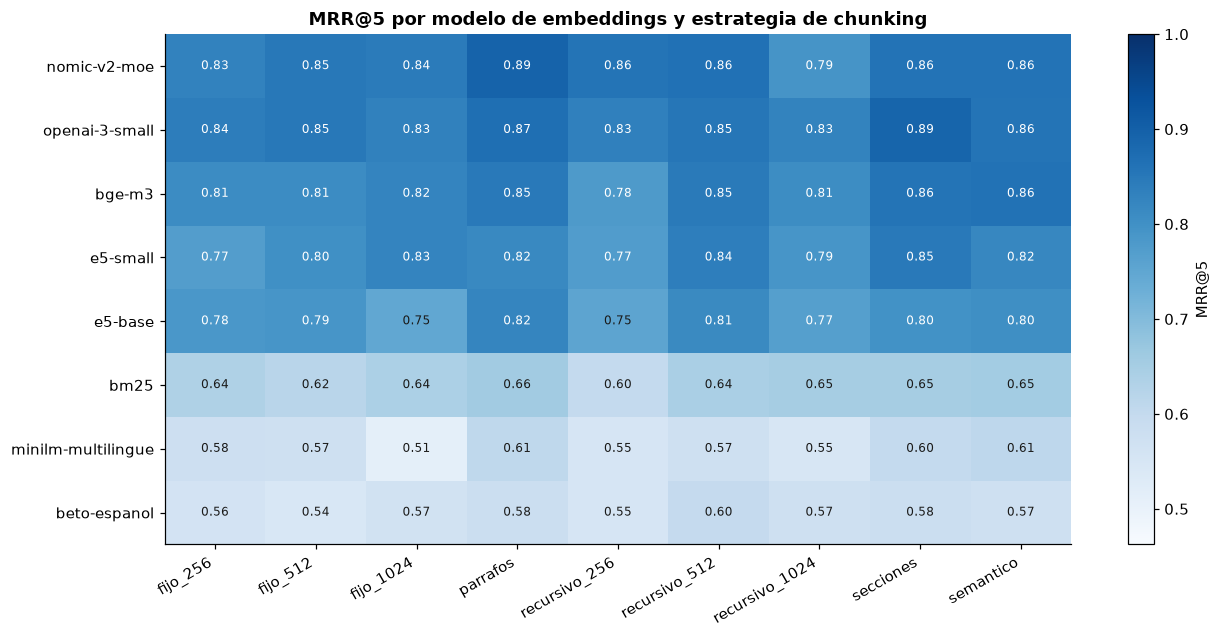

,modelo,estrategia,hit@1,hit@3,hit@5,mrr@5,cobertura,auc_fuera_alcance
57,nomic-v2-moe,parrafos,0.861,0.931,0.931,0.894,1.0,0.994
70,openai-3-small,secciones,0.833,0.944,0.972,0.891,1.0,0.996
66,openai-3-small,parrafos,0.806,0.944,0.958,0.869,1.0,1.000
60,nomic-v2-moe,recursivo_512,0.806,0.931,0.944,0.865,1.0,0.986
17,bge-m3,semantico,0.778,0.944,0.986,0.863,1.0,0.992
61,nomic-v2-moe,secciones,0.819,0.903,0.903,0.861,1.0,0.981
62,nomic-v2-moe,semantico,0.806,0.903,0.931,0.860,1.0,0.989
16,bge-m3,secciones,0.792,0.917,0.958,0.859,1.0,0.990
59,nomic-v2-moe,recursivo_256,0.819,0.903,0.917,0.859,1.0,0.992
71,openai-3-small,semantico,0.792,0.931,0.958,0.858,1.0,0.997


In [17]:
df_grid = (df_resultados.groupby(["modelo", "estrategia"]).apply(lambda d: pd.Series(resumir(d))).reset_index())
df_grid.to_csv(RESULTADOS_DIR / "exp1_grid.csv", index=False)

orden_estrategias = list(chunks_pdf)
orden_modelos = df_grid.groupby("modelo")["mrr@5"].mean().sort_values(ascending=False).index.tolist()
pivote = df_grid.pivot(index="modelo", columns="estrategia", values="mrr@5").loc[orden_modelos, orden_estrategias]

fig, ax = plt.subplots(figsize=(12, 0.55 * len(orden_modelos) + 1.5))
im = ax.imshow(pivote.values, cmap="Blues", vmin=max(0, pivote.values.min() - 0.05), vmax=1, aspect="auto")
ax.set_xticks(range(len(orden_estrategias)), orden_estrategias, rotation=30, ha="right")
ax.set_yticks(range(len(orden_modelos)), orden_modelos)
ax.grid(False)
umbral_texto = (pivote.values.min() + 1) / 2
for i in range(pivote.shape[0]):
    for j in range(pivote.shape[1]):
        v = pivote.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if v > umbral_texto else "#1a1a19")
ax.set_title("MRR@5 por modelo de embeddings y estrategia de chunking")
fig.colorbar(im, ax=ax, label="MRR@5")
plt.tight_layout(); plt.show()

display(df_grid.sort_values("mrr@5", ascending=False).head(15).round(3))

### 5.2 Comparación de modelos de embeddings

In [18]:
mejor_por_modelo = df_grid.loc[df_grid.groupby("modelo")["mrr@5"].idxmax()].set_index("modelo")
promedio_por_modelo = df_grid.groupby("modelo")[["mrr@5", "hit@1", "hit@5", "auc_fuera_alcance"]].mean()

df_modelos = (mejor_por_modelo[["estrategia", "mrr@5", "hit@1", "hit@3", "hit@5", "auc_fuera_alcance"]]
              .rename(columns=lambda c: f"mejor_{c}" if c != "estrategia" else "mejor_estrategia")
              .join(promedio_por_modelo.add_prefix("prom_"))
              .join(df_info_modelos, how="left")
              .sort_values("mejor_mrr@5", ascending=False))
df_modelos.to_csv(RESULTADOS_DIR / "exp1_modelos.csv")
display(df_modelos.round(3))

,mejor_estrategia,mejor_mrr@5,mejor_hit@1,mejor_hit@3,mejor_hit@5,mejor_auc_fuera_alcance,prom_mrr@5,prom_hit@1,prom_hit@5,prom_auc_fuera_alcance,params_M,dim,max_tokens,carga_s,chunks_por_s,latencia_query_ms
modelo,,,,,,,,,,,,,,,,
nomic-v2-moe,parrafos,0.894,0.861,0.931,0.931,0.994,0.850,0.796,0.921,0.986,475.0,768.0,NaN,0.000,88.825,10.686
openai-3-small,secciones,0.891,0.833,0.944,0.972,0.996,0.850,0.781,0.955,0.998,NaN,1536.0,8191.0,0.238,50.537,324.488
bge-m3,semantico,0.863,0.778,0.944,0.986,0.992,0.827,0.736,0.961,0.994,568.0,1024.0,8192.0,4.096,91.876,13.848
e5-small,secciones,0.848,0.778,0.917,0.958,0.992,0.809,0.728,0.937,0.994,118.0,384.0,512.0,3.692,673.849,5.204
e5-base,parrafos,0.824,0.750,0.875,0.958,0.985,0.786,0.702,0.927,0.980,278.0,768.0,512.0,3.561,255.884,6.728
bm25,parrafos,0.656,0.528,0.750,0.847,0.778,0.639,0.509,0.838,0.777,NaN,NaN,NaN,NaN,NaN,NaN
minilm-multilingue,semantico,0.610,0.514,0.681,0.764,0.938,0.572,0.481,0.724,0.938,118.0,384.0,128.0,2.757,845.198,5.367
beto-espanol,recursivo_512,0.599,0.472,0.722,0.833,0.922,0.571,0.435,0.802,0.923,110.0,768.0,512.0,2.505,287.717,6.650


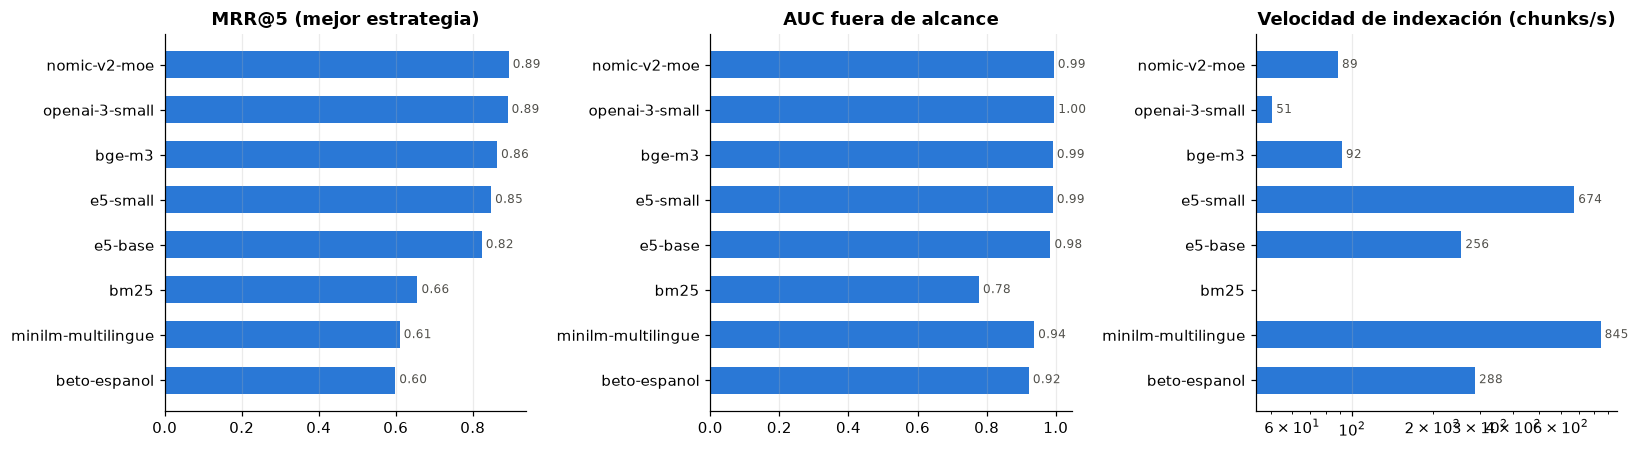

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
d = df_modelos.sort_values("mejor_mrr@5")
for ax, col, titulo in zip(axes, ["mejor_mrr@5", "mejor_auc_fuera_alcance", "chunks_por_s"],
                           ["MRR@5 (mejor estrategia)", "AUC fuera de alcance", "Velocidad de indexación (chunks/s)"]):
    vals = d[col]
    ax.barh(d.index, vals.fillna(0), color=COLOR_BARRA, height=0.6)
    for y, v in enumerate(vals):
        ax.text((0 if pd.isna(v) else v), y, " n/a" if pd.isna(v) else f" {v:.2f}" if v < 10 else f" {v:,.0f}",
                va="center", fontsize=8, color="#52514c")
    ax.set_title(titulo); ax.grid(axis="y", visible=False)
    if col == "chunks_por_s":
        ax.set_xscale("log")
plt.tight_layout(); plt.show()

### 5.3 Robustez en español y por fuente

Se usa la **mejor estrategia de cada modelo**. El desglose por variante muestra si el modelo se degrada con lenguaje coloquial, sin tildes o con errores; el desglose por fuente muestra en qué tipo de documento falla (p. ej. códigos de pedido).

In [20]:
mejor_combo = mejor_por_modelo["estrategia"].to_dict()
df_mejor = pd.concat([df_resultados[(df_resultados["modelo"] == m) & (df_resultados["estrategia"] == e)]
                      for m, e in mejor_combo.items()])
df_en = df_mejor[df_mejor["en_alcance"]]

por_variante = df_en.pivot_table(index="modelo", columns="variante", values="rr@5", aggfunc="mean").loc[orden_modelos]
por_fuente = df_en.pivot_table(index="modelo", columns="fuente", values="rr@5", aggfunc="mean").loc[orden_modelos]
print("MRR@5 por variante de pregunta"); display(por_variante.round(3))
print("MRR@5 por fuente"); display(por_fuente.round(3))
por_variante.to_csv(RESULTADOS_DIR / "exp1_por_variante.csv"); por_fuente.to_csv(RESULTADOS_DIR / "exp1_por_fuente.csv")

MRR@5 por variante de pregunta


variante,coloquial,con_errores,formal,sin_tildes
modelo,,,,
nomic-v2-moe,0.818,1.000,0.880,0.923
openai-3-small,0.859,1.000,0.876,0.885
bge-m3,0.826,0.870,0.847,0.938
e5-small,0.727,0.796,0.863,0.938
e5-base,0.764,0.837,0.825,0.862
bm25,0.427,0.620,0.666,0.846
minilm-multilingue,0.659,0.370,0.574,0.846
beto-espanol,0.561,0.494,0.667,0.500


MRR@5 por fuente


fuente,catalogo,faq,inventario,pedidos,politica
modelo,,,,,
nomic-v2-moe,1.000,0.967,0.917,0.750,0.870
openai-3-small,1.000,1.000,1.000,0.604,0.853
bge-m3,1.000,0.922,0.917,0.681,0.840
e5-small,0.767,0.917,0.917,0.723,0.833
e5-base,0.547,0.950,0.875,0.712,0.816
bm25,0.240,0.767,0.715,1.000,0.562
minilm-multilingue,0.800,0.711,0.725,0.000,0.643
beto-espanol,0.300,0.889,0.722,0.479,0.493


### 5.4 Intervalos de confianza (bootstrap 95%) de las mejores combinaciones

Con ~70 preguntas, diferencias pequeñas pueden ser ruido. Si los intervalos se solapan mucho, la diferencia no es concluyente y se deben priorizar otros criterios (costo, velocidad).

,modelo,estrategia,mrr@5,ic_inf,ic_sup
0,nomic-v2-moe,parrafos,0.894,0.826,0.951
1,openai-3-small,secciones,0.891,0.828,0.945
2,openai-3-small,parrafos,0.869,0.803,0.926
3,nomic-v2-moe,recursivo_512,0.865,0.791,0.928
4,bge-m3,semantico,0.863,0.802,0.922
5,nomic-v2-moe,secciones,0.861,0.785,0.931
6,nomic-v2-moe,semantico,0.860,0.784,0.924
7,bge-m3,secciones,0.859,0.789,0.921


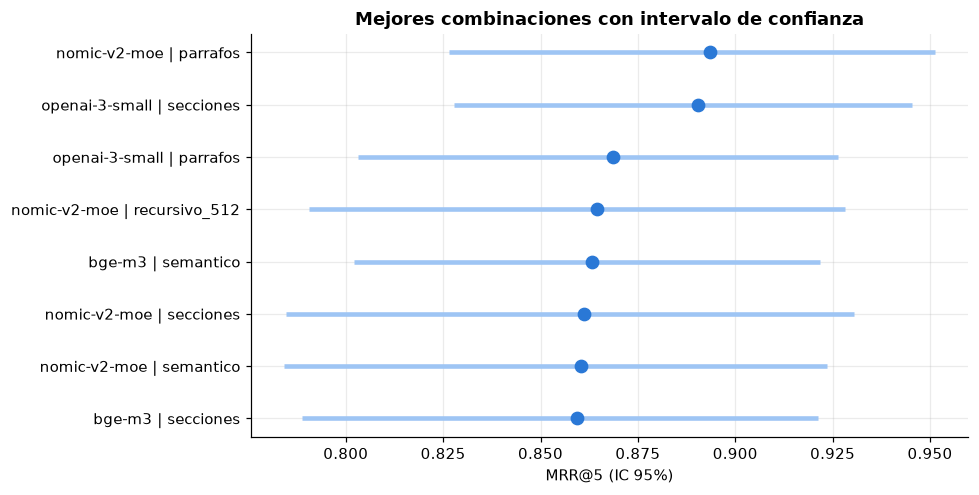

In [21]:
top = df_grid.sort_values("mrr@5", ascending=False).head(8)
filas = []
for r in top.itertuples():
    valores = df_resultados[(df_resultados["modelo"] == r.modelo) & (df_resultados["estrategia"] == r.estrategia) & df_resultados["en_alcance"]]["rr@5"]
    lo, hi = ic_bootstrap(valores)
    filas.append({"modelo": r.modelo, "estrategia": r.estrategia, "mrr@5": valores.mean(), "ic_inf": lo, "ic_sup": hi})
df_ic = pd.DataFrame(filas)
display(df_ic.round(3))

fig, ax = plt.subplots(figsize=(9, 0.45 * len(df_ic) + 1))
etiquetas = df_ic["modelo"] + " | " + df_ic["estrategia"]
ax.errorbar(df_ic["mrr@5"], range(len(df_ic)), xerr=[df_ic["mrr@5"] - df_ic["ic_inf"], df_ic["ic_sup"] - df_ic["mrr@5"]],
            fmt="o", color=COLOR_BARRA, ecolor="#9ec5f4", elinewidth=3, markersize=8)
ax.set_yticks(range(len(df_ic)), etiquetas); ax.invert_yaxis()
ax.set_xlabel("MRR@5 (IC 95%)"); ax.set_title("Mejores combinaciones con intervalo de confianza")
plt.tight_layout(); plt.show()

### 5.5 Comparación de estrategias de chunking (promedio sobre modelos densos)

,mrr@5,hit@1,hit@5,cobertura,chunks_pdf,largo_prom,mrr@5_bm25
estrategia,,,,,,,
parrafos,0.777,0.694,0.907,1.0,37,253.59,0.656
secciones,0.777,0.698,0.895,1.0,15,627.00,0.650
semantico,0.770,0.685,0.901,1.0,16,587.75,0.655
recursivo_512,0.770,0.681,0.915,1.0,26,374.31,0.644
fijo_512,0.746,0.649,0.901,1.0,22,503.91,0.619
fijo_256,0.738,0.661,0.877,1.0,44,253.32,0.636
fijo_1024,0.736,0.645,0.881,1.0,11,1000.82,0.640
recursivo_1024,0.729,0.639,0.875,1.0,12,806.17,0.650
recursivo_256,0.728,0.641,0.857,1.0,57,167.70,0.599


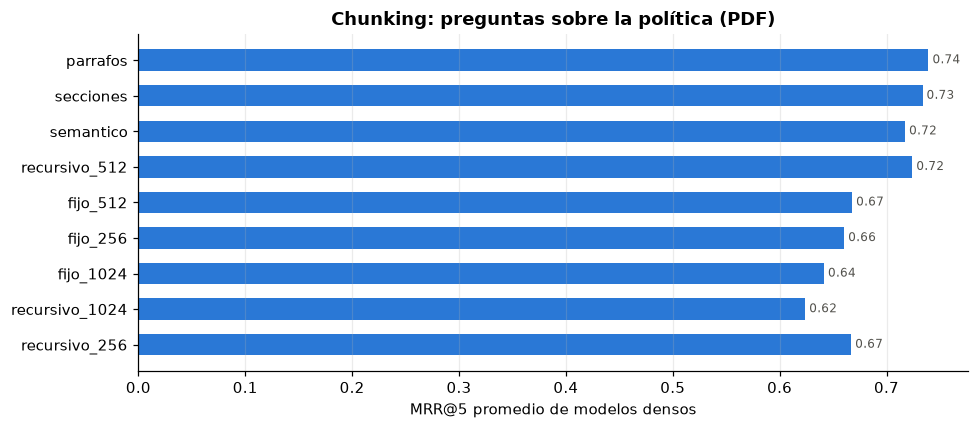

In [22]:
densos = df_grid[df_grid["modelo"] != "bm25"]
df_chunking = (densos.groupby("estrategia")[["mrr@5", "hit@1", "hit@5", "cobertura"]].mean()
               .join(df_estrategias[["chunks_pdf", "largo_prom"]])
               .join(df_grid[df_grid["modelo"] == "bm25"].set_index("estrategia")[["mrr@5"]].rename(columns={"mrr@5": "mrr@5_bm25"}))
               .sort_values("mrr@5", ascending=False))
df_chunking.to_csv(RESULTADOS_DIR / "exp1_chunking.csv")
display(df_chunking.round(3))

# Solo preguntas del PDF: aqui es donde el chunking del texto realmente cambia
pdf_only = (df_resultados[(df_resultados["fuente"] == "politica") & (df_resultados["modelo"] != "bm25")]
            .groupby("estrategia")["rr@5"].mean().reindex(df_chunking.index))
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(pdf_only.index[::-1], pdf_only.values[::-1], color=COLOR_BARRA, height=0.6)
for y, v in enumerate(pdf_only.values[::-1]):
    ax.text(v, y, f" {v:.2f}", va="center", fontsize=8, color="#52514c")
ax.set_xlabel("MRR@5 promedio de modelos densos"); ax.set_title("Chunking: preguntas sobre la política (PDF)")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

### 5.6 Truncamiento: chunks que superan la ventana del modelo

Si un chunk tiene más tokens que el máximo del modelo, el final se ignora al generar el embedding. Esto penaliza especialmente a modelos con ventana corta (MiniLM: 128 tokens) cuando se usan chunks grandes (secciones, 1024 caracteres).

In [23]:
filas = []
for modelo, (max_tok, tokens) in tokens_por_modelo.items():
    if max_tok is None or not any(tokens.values()):
        continue
    for estrategia, chunks in chunks_pdf.items():
        n_tok = [tokens[c["texto"]] for c in chunks]
        filas.append({"modelo": modelo, "estrategia": estrategia, "tokens_prom": np.mean(n_tok),
                      "pct_truncado": np.mean([t > max_tok for t in n_tok])})
df_trunc = pd.DataFrame(filas)
if len(df_trunc):
    display(df_trunc.pivot(index="modelo", columns="estrategia", values="pct_truncado")[orden_estrategias].round(2))
    df_trunc.to_csv(RESULTADOS_DIR / "exp1_truncamiento.csv", index=False)

estrategia,fijo_256,fijo_512,fijo_1024,parrafos,recursivo_256,recursivo_512,recursivo_1024,secciones,semantico
modelo,,,,,,,,,
beto-espanol,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0
bge-m3,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0
e5-base,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0
e5-small,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0
minilm-multilingue,0.0,0.05,1.0,0.0,0.0,0.0,1.0,0.6,0.5


### 5.7 Detección de preguntas fuera de alcance

Distribución del puntaje máximo de similitud para preguntas dentro y fuera de alcance (mejor estrategia de cada modelo). Si las distribuciones no se solapan, un umbral simple permite que el asistente responda "no tengo esa información".

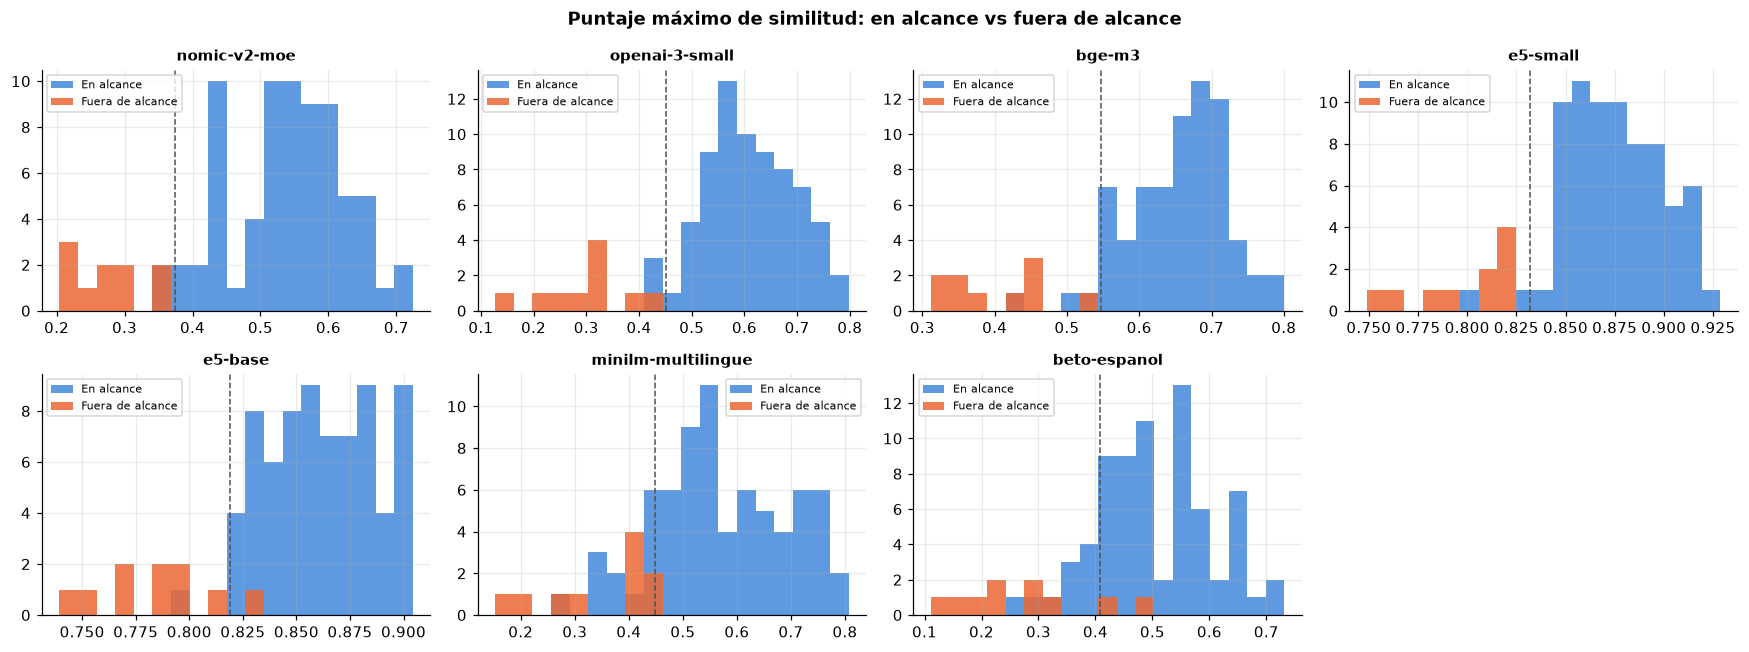

,umbral,exactitud_balanceada,pct_en_alcance_aceptadas,pct_fuera_rechazadas
modelo,,,,
e5-small,0.832,0.993,0.986,1.0
nomic-v2-moe,0.374,0.986,0.972,1.0
openai-3-small,0.452,0.979,0.958,1.0
bge-m3,0.548,0.979,0.958,1.0
e5-base,0.819,0.943,0.986,0.9
minilm-multilingue,0.448,0.931,0.861,1.0
beto-espanol,0.407,0.881,0.861,0.9


In [24]:
modelos_densos = [m for m in orden_modelos if m != "bm25"]
n = len(modelos_densos)
cols = min(4, n); filas_fig = int(np.ceil(n / cols))
fig, axes = plt.subplots(filas_fig, cols, figsize=(4 * cols, 3 * filas_fig), squeeze=False)
umbrales = []
for ax, m in zip(axes.flat, modelos_densos):
    d = df_mejor[df_mejor["modelo"] == m]
    dentro, fuera = d[d["en_alcance"]]["puntaje_max"], d[~d["en_alcance"]]["puntaje_max"]
    bins = np.linspace(d["puntaje_max"].min(), d["puntaje_max"].max(), 20)
    ax.hist(dentro, bins=bins, alpha=0.75, color=PALETA[0], label="En alcance")
    ax.hist(fuera, bins=bins, alpha=0.85, color=PALETA[1], label="Fuera de alcance")
    # umbral que maximiza exactitud balanceada
    candidatos = np.unique(d["puntaje_max"])
    exactitud = [((dentro >= u).mean() + (fuera < u).mean()) / 2 for u in candidatos]
    u = candidatos[int(np.argmax(exactitud))]
    umbrales.append({"modelo": m, "umbral": u, "exactitud_balanceada": max(exactitud),
                     "pct_en_alcance_aceptadas": (dentro >= u).mean(), "pct_fuera_rechazadas": (fuera < u).mean()})
    ax.axvline(u, color="#52514c", linestyle="--", linewidth=1)
    ax.set_title(m, fontsize=10); ax.legend(fontsize=7)
for ax in list(axes.flat)[n:]:
    ax.axis("off")
plt.suptitle("Puntaje máximo de similitud: en alcance vs fuera de alcance", fontweight="bold")
plt.tight_layout(); plt.show()
df_umbrales = pd.DataFrame(umbrales).set_index("modelo").sort_values("exactitud_balanceada", ascending=False)
df_umbrales.to_csv(RESULTADOS_DIR / "exp1_umbrales.csv")
display(df_umbrales.round(3))

## 6. Experimento 2: datos estructurados y búsqueda híbrida

### 6.1 Por registro vs texto aplanado

Se toman los **3 mejores modelos densos** del Experimento 1 (con su mejor estrategia para el PDF) y se compara:

- **A. Por registro:** una fila / un par pregunta-respuesta = un chunk.
- **B. Texto aplanado:** cada tabla/JSON se convierte en un solo texto y se segmenta con `recursivo_512` (lo que haría un loader genérico).

Solo se evalúan las preguntas de inventario, FAQ y pedidos.

In [25]:
def aplanado(fuente):
    texto = "\n".join(r["texto"] for r in registros_estructurados if r["fuente"] == fuente)
    return chunk_recursivo(512, texto, fuente)


registros_aplanados = aplanado("inventario") + aplanado("faq") + aplanado("pedidos")
top3 = [m for m in orden_modelos if m != "bm25" and m in VECTORES][:3]
mascara_estruct = df_preguntas["fuente"].isin(["inventario", "faq", "pedidos"]).values
preguntas_estruct = df_preguntas[mascara_estruct].reset_index(drop=True)

filas = []
for modelo in top3 + ["bm25"]:
    estrategia_pdf = mejor_combo[modelo]
    for variante, estruct in [("A_por_registro", registros_estructurados), ("B_aplanado", registros_aplanados)]:
        chunks = chunks_pdf[estrategia_pdf] + chunks_catalogo + estruct
        rel = matriz_relevancia(chunks, preguntas_estruct)
        if modelo == "bm25":
            punt = BM25([c["texto"] for c in chunks]).puntajes(preguntas_estruct["pregunta"].tolist())
        else:
            cache = VECTORES[modelo]["cache"]
            nuevos = [c["texto"] for c in chunks if c["texto"] not in cache]
            if nuevos:
                emb = cargar_embedder(modelo)
                cache.update(zip(nuevos, emb.encode_docs(nuevos)))
                emb.liberar()
            punt = VECTORES[modelo]["consultas"][mascara_estruct] @ np.stack([cache[c["texto"]] for c in chunks]).T
        d = evaluar(punt, rel, preguntas_estruct)
        filas.append({"modelo": modelo, "variante": variante, "chunks_estructurados": len(estruct),
                      **{f"mrr@5_{f}": d[d["fuente"] == f]["rr@5"].mean() for f in ["inventario", "faq", "pedidos"]},
                      "mrr@5_total": d["rr@5"].mean(), "hit@1_total": d["hit@1"].mean()})
df_estruct = pd.DataFrame(filas)
df_estruct.to_csv(RESULTADOS_DIR / "exp2_estructurados.csv", index=False)
display(df_estruct.round(3))

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

,modelo,variante,chunks_estructurados,mrr@5_inventario,mrr@5_faq,mrr@5_pedidos,mrr@5_total,hit@1_total
0,nomic-v2-moe,A_por_registro,90,0.917,0.967,0.750,0.900,0.886
1,nomic-v2-moe,B_aplanado,72,0.917,0.856,0.542,0.805,0.771
2,openai-3-small,A_por_registro,90,1.000,1.000,0.604,0.910,0.886
3,openai-3-small,B_aplanado,72,1.000,0.889,0.567,0.853,0.800
4,bge-m3,A_por_registro,90,0.917,0.922,0.681,0.865,0.800
5,bge-m3,B_aplanado,72,0.958,0.922,0.510,0.840,0.771
6,bm25,A_por_registro,90,0.715,0.767,1.000,0.802,0.686
7,bm25,B_aplanado,72,0.792,0.767,1.000,0.829,0.743


### 6.2 Búsqueda híbrida (denso + BM25)

Exploratorio: si los modelos densos fallan con códigos exactos (`ECO-1003`, SKUs), combinar su ranking con BM25 mediante **Reciprocal Rank Fusion** (RRF, `score = Σ 1/(60 + rank)`) podría corregirlo. Se evalúa con los 3 mejores modelos y su mejor estrategia.

In [26]:
def rrf(*matrices_puntaje, k_rrf=60):
    total = 0
    for m in matrices_puntaje:
        rangos = np.argsort(np.argsort(-m, axis=1), axis=1) + 1
        total = total + 1 / (k_rrf + rangos)
    return total


filas = []
for modelo in top3:
    estrategia = mejor_combo[modelo]
    chunks = ESTRATEGIAS[estrategia]
    denso = VECTORES[modelo]["consultas"] @ np.stack([VECTORES[modelo]["cache"][c["texto"]] for c in chunks]).T
    lexico = BM25([c["texto"] for c in chunks]).puntajes(consultas)
    for nombre, punt in [("denso", denso), ("hibrido_rrf", rrf(denso, lexico))]:
        d = evaluar(punt, RELEVANCIA[estrategia])
        en = d[d["en_alcance"]]
        filas.append({"modelo": modelo, "estrategia": estrategia, "metodo": nombre, "mrr@5": en["rr@5"].mean(),
                      "hit@1": en["hit@1"].mean(),
                      **{f"mrr@5_{f}": en[en["fuente"] == f]["rr@5"].mean() for f in ["politica", "catalogo", "inventario", "faq", "pedidos"]}})
df_hibrido = pd.DataFrame(filas)
df_hibrido.to_csv(RESULTADOS_DIR / "exp2_hibrido.csv", index=False)
display(df_hibrido.round(3))

,modelo,estrategia,metodo,mrr@5,hit@1,mrr@5_politica,mrr@5_catalogo,mrr@5_inventario,mrr@5_faq,mrr@5_pedidos
0,nomic-v2-moe,parrafos,denso,0.894,0.861,0.870,1.0,0.917,0.967,0.750
1,nomic-v2-moe,parrafos,hibrido_rrf,0.791,0.694,0.702,0.9,0.794,0.867,0.938
2,openai-3-small,secciones,denso,0.891,0.833,0.853,1.0,1.000,1.000,0.604
3,openai-3-small,secciones,hibrido_rrf,0.811,0.694,0.690,1.0,0.903,0.900,0.875
4,bge-m3,semantico,denso,0.863,0.778,0.840,1.0,0.917,0.922,0.681
5,bge-m3,semantico,hibrido_rrf,0.802,0.694,0.654,1.0,0.861,0.900,1.000


## 7. Experimento 3: bases de datos vectoriales

Se usan los vectores del **mejor modelo** y la **mejor estrategia** del Experimento 1. Cada base se envuelve en un adaptador con la misma interfaz (`insertar`, `buscar`, `buscar_filtrado`).

Mediciones:

1. **Corpus real:** tiempo de inserción, latencia por consulta (mediana y p95), *recall@5* frente a la búsqueda exacta (fuerza bruta con NumPy) y MRR@5. Prueba de **filtro por metadatos** (`fuente = pedidos`).
2. **Escala:** vectores sintéticos (1k, 10k, 100k) con la dimensión del mejor modelo: inserción, latencia y recall@10.

**Weaviate:** servidor local con `docker compose up -d` (archivo `docker-compose.yml`).
**Pinecone:** índice serverless en AWS us-east-1 creado y borrado por el notebook (requiere `PINECONE_API_KEY`). Se excluye de la prueba de escala para no consumir la capa gratuita; su latencia incluye la red, que es parte del costo real de un servicio SaaS.

In [27]:
import uuid


class VDB:
    nombre = ""
    filtro_nativo = True
    despliegue = ""

    def insertar(self, vectores, fuentes): ...
    def buscar(self, q, k): ...
    def buscar_filtrado(self, q, k, fuente): ...
    def cerrar(self): pass


class ChromaVDB(VDB):
    nombre, despliegue = "chroma", "embebida"

    def __init__(self, dim):
        import chromadb
        self.cliente = chromadb.EphemeralClient()
        self.col = self.cliente.create_collection(f"exp_{uuid.uuid4().hex[:8]}", metadata={"hnsw:space": "cosine"})

    def insertar(self, vectores, fuentes):
        for i in range(0, len(vectores), 5000):
            ids = [str(j) for j in range(i, min(i + 5000, len(vectores)))]
            self.col.add(ids=ids, embeddings=vectores[i:i + 5000].tolist(),
                         metadatas=[{"fuente": f} for f in fuentes[i:i + 5000]])

    def buscar(self, q, k):
        return [int(i) for i in self.col.query(query_embeddings=[q.tolist()], n_results=k)["ids"][0]]

    def buscar_filtrado(self, q, k, fuente):
        r = self.col.query(query_embeddings=[q.tolist()], n_results=k, where={"fuente": fuente})
        return [int(i) for i in r["ids"][0]]

    def cerrar(self):
        self.cliente.delete_collection(self.col.name)


class FaissVDB(VDB):
    filtro_nativo, despliegue = False, "libreria"

    def __init__(self, dim, tipo="flat"):
        import faiss
        # En macOS, FAISS y PyTorch traen cada uno su OpenMP; con varios hilos el
        # proceso puede abortar. Un hilo evita el conflicto (las busquedas
        # individuales de FAISS son de un hilo de todos modos).
        faiss.omp_set_num_threads(1)
        self.nombre = f"faiss_{tipo}"
        if tipo == "flat":
            self.indice = faiss.IndexFlatIP(dim)
        else:
            self.indice = faiss.IndexHNSWFlat(dim, 32, faiss.METRIC_INNER_PRODUCT)
            self.indice.hnsw.efSearch = 64
        self.fuentes = []

    def insertar(self, vectores, fuentes):
        self.indice.add(np.ascontiguousarray(vectores, dtype=np.float32))
        self.fuentes += list(fuentes)

    def buscar(self, q, k):
        return self.indice.search(q.reshape(1, -1).astype(np.float32), k)[1][0].tolist()

    def buscar_filtrado(self, q, k, fuente):
        # FAISS no guarda metadatos: se sobre-recupera y se filtra despues
        ids = self.indice.search(q.reshape(1, -1).astype(np.float32), min(k * 20, self.indice.ntotal))[1][0]
        return [int(i) for i in ids if i >= 0 and self.fuentes[i] == fuente][:k]


class QdrantVDB(VDB):
    nombre, despliegue = "qdrant_local", "embebida (local) / servidor"

    def __init__(self, dim):
        from qdrant_client import QdrantClient
        from qdrant_client.models import Distance, VectorParams
        self.cliente = QdrantClient(":memory:")
        self.col = f"exp_{uuid.uuid4().hex[:8]}"
        self.cliente.create_collection(self.col, vectors_config=VectorParams(size=dim, distance=Distance.COSINE))

    def insertar(self, vectores, fuentes):
        self.cliente.upload_collection(self.col, vectors=vectores, payload=[{"fuente": f} for f in fuentes],
                                       ids=list(range(len(vectores))))

    def buscar(self, q, k):
        return [p.id for p in self.cliente.query_points(self.col, query=q.tolist(), limit=k).points]

    def buscar_filtrado(self, q, k, fuente):
        from qdrant_client.models import FieldCondition, Filter, MatchValue
        filtro = Filter(must=[FieldCondition(key="fuente", match=MatchValue(value=fuente))])
        return [p.id for p in self.cliente.query_points(self.col, query=q.tolist(), limit=k, query_filter=filtro).points]

    def cerrar(self):
        self.cliente.close()


class WeaviateVDB(VDB):
    nombre, despliegue = "weaviate", "servidor (Docker) / nube"

    def __init__(self, dim):
        import weaviate
        from weaviate.classes.config import Configure, DataType, Property, VectorDistances
        self.cliente = weaviate.connect_to_local()
        self.nombre_col = f"Exp{uuid.uuid4().hex[:8]}"
        self.col = self.cliente.collections.create(
            self.nombre_col,
            vector_config=Configure.Vectors.self_provided(
                vector_index_config=Configure.VectorIndex.hnsw(distance_metric=VectorDistances.COSINE)),
            properties=[Property(name="cid", data_type=DataType.INT), Property(name="fuente", data_type=DataType.TEXT)])

    def insertar(self, vectores, fuentes):
        with self.col.batch.fixed_size(batch_size=500) as batch:
            for i, (v, f) in enumerate(zip(vectores, fuentes)):
                batch.add_object(properties={"cid": i, "fuente": f}, vector=v.tolist())

    def buscar(self, q, k):
        return [o.properties["cid"] for o in self.col.query.near_vector(near_vector=q.tolist(), limit=k, return_properties=["cid"]).objects]

    def buscar_filtrado(self, q, k, fuente):
        from weaviate.classes.query import Filter
        r = self.col.query.near_vector(near_vector=q.tolist(), limit=k, filters=Filter.by_property("fuente").equal(fuente),
                                       return_properties=["cid"])
        return [o.properties["cid"] for o in r.objects]

    def cerrar(self):
        self.cliente.collections.delete(self.nombre_col)
        self.cliente.close()


class PineconeVDB(VDB):
    nombre, despliegue = "pinecone", "SaaS (nube)"

    def __init__(self, dim):
        from pinecone import Pinecone, ServerlessSpec
        self.pc = Pinecone(api_key=os.environ["PINECONE_API_KEY"])
        self.nombre_idx = "ecomarket-exp"
        if self.nombre_idx in self.pc.list_indexes().names():
            self.pc.delete_index(self.nombre_idx)
        self.pc.create_index(self.nombre_idx, dimension=dim, metric="cosine", spec=ServerlessSpec(cloud="aws", region="us-east-1"))
        self.idx = self.pc.Index(self.nombre_idx)

    def insertar(self, vectores, fuentes):
        datos = [(str(i), v.tolist(), {"fuente": f}) for i, (v, f) in enumerate(zip(vectores, fuentes))]
        self.idx.upsert(vectors=datos, batch_size=100, show_progress=False)
        limite = time.time() + 120
        while self.idx.describe_index_stats().total_vector_count < len(datos) and time.time() < limite:
            time.sleep(1)  # Pinecone es eventualmente consistente

    def buscar(self, q, k):
        return [int(m.id) for m in self.idx.query(vector=q.tolist(), top_k=k).matches]

    def buscar_filtrado(self, q, k, fuente):
        return [int(m.id) for m in self.idx.query(vector=q.tolist(), top_k=k, filter={"fuente": {"$eq": fuente}}).matches]

    def cerrar(self):
        self.pc.delete_index(self.nombre_idx)


FABRICAS_VDB = {
    "chroma": ChromaVDB,
    "faiss_flat": lambda d: FaissVDB(d, "flat"),
    "faiss_hnsw": lambda d: FaissVDB(d, "hnsw"),
    "qdrant_local": QdrantVDB,
}
if EJECUTAR_WEAVIATE:
    FABRICAS_VDB["weaviate"] = WeaviateVDB
if EJECUTAR_PINECONE:
    FABRICAS_VDB["pinecone"] = PineconeVDB

print("Bases a evaluar:", list(FABRICAS_VDB))

Bases a evaluar: ['chroma', 'faiss_flat', 'faiss_hnsw', 'qdrant_local', 'weaviate', 'pinecone']


### 7.1 Corpus real

In [28]:
mejor_fila = df_grid[df_grid["modelo"] != "bm25"].sort_values("mrr@5", ascending=False).iloc[0]
MODELO_VDB, ESTRATEGIA_VDB = mejor_fila["modelo"], mejor_fila["estrategia"]
chunks_vdb = ESTRATEGIAS[ESTRATEGIA_VDB]
X = np.stack([VECTORES[MODELO_VDB]["cache"][c["texto"]] for c in chunks_vdb]).astype(np.float32)
Q = VECTORES[MODELO_VDB]["consultas"].astype(np.float32)
fuentes_vdb = [c["fuente"] for c in chunks_vdb]
print(f"Modelo: {MODELO_VDB} | Estrategia: {ESTRATEGIA_VDB} | Vectores: {X.shape}")

exacto = np.argsort(-(Q @ X.T), axis=1)[:, :K]   # referencia: busqueda exacta
preg_pedidos = np.where(df_preguntas["fuente"] == "pedidos")[0]

filas = []
for nombre, fabrica in FABRICAS_VDB.items():
    try:
        vdb = fabrica(X.shape[1])
        t0 = time.perf_counter(); vdb.insertar(X, fuentes_vdb); t_ins = time.perf_counter() - t0
        lat, resultados = [], []
        for q in Q:
            t0 = time.perf_counter(); resultados.append(vdb.buscar(q, K)); lat.append((time.perf_counter() - t0) * 1000)
        recall = np.mean([len(set(r) & set(e)) / K for r, e in zip(resultados, exacto)])
        punt = np.full((len(Q), len(X)), -np.inf)
        for i, r in enumerate(resultados):
            punt[i, r] = np.arange(len(r), 0, -1)  # orden devuelto por la base
        mrr = evaluar(np.where(np.isinf(punt), -1e9, punt), RELEVANCIA[ESTRATEGIA_VDB]).query("en_alcance")["rr@5"].mean()
        filtro_ok = np.mean([all(fuentes_vdb[i] == "pedidos" for i in vdb.buscar_filtrado(Q[q], K, "pedidos")) for q in preg_pedidos])
        filas.append({"base": nombre, "insercion_ms": t_ins * 1000, "latencia_p50_ms": np.median(lat),
                      "latencia_p95_ms": np.percentile(lat, 95), "recall@5_vs_exacto": recall, "mrr@5": mrr,
                      "filtro_correcto": filtro_ok, "filtro_nativo": vdb.filtro_nativo, "despliegue": vdb.despliegue})
        vdb.cerrar()
    except Exception as e:
        print(f"ERROR con {nombre}: {e!r}")
df_vdb_real = pd.DataFrame(filas).set_index("base")
df_vdb_real.to_csv(RESULTADOS_DIR / "exp3_vdb_corpus_real.csv")
display(df_vdb_real.round(3))

Modelo: nomic-v2-moe | Estrategia: parrafos | Vectores: (129, 768)


,insercion_ms,latencia_p50_ms,latencia_p95_ms,recall@5_vs_exacto,mrr@5,filtro_correcto,filtro_nativo,despliegue
base,,,,,,,,
chroma,18.544,0.358,0.447,1.0,0.894,1.0,True,embebida
faiss_flat,0.179,0.007,0.011,1.0,0.894,1.0,False,libreria
faiss_hnsw,2.142,0.016,0.024,1.0,0.894,1.0,False,libreria
qdrant_local,4.927,0.276,0.306,1.0,0.894,1.0,True,embebida (local) / servidor
weaviate,1062.567,0.870,1.458,1.0,0.894,1.0,True,servidor (Docker) / nube
pinecone,1615.779,99.926,186.516,1.0,0.894,1.0,True,SaaS (nube)


### 7.2 Prueba de escala (vectores sintéticos)

Vectores aleatorios normalizados con la dimensión del mejor modelo. Son un caso **más difícil** que los datos reales para los índices aproximados (HNSW), porque no tienen estructura de vecindad. El recall@10 se mide contra búsqueda exacta.

In [29]:
dim = X.shape[1]
filas = []
for n in TAMANOS_ESCALA:
    base = rng.standard_normal((n, dim), dtype=np.float32)
    base /= np.linalg.norm(base, axis=1, keepdims=True)
    consultas_sint = rng.standard_normal((N_CONSULTAS_ESCALA, dim), dtype=np.float32)
    consultas_sint /= np.linalg.norm(consultas_sint, axis=1, keepdims=True)
    exacto_sint = np.argsort(-(consultas_sint @ base.T), axis=1)[:, :10]
    fuentes_sint = rng.choice(["politica", "inventario", "faq", "pedidos"], size=n).tolist()
    for nombre, fabrica in FABRICAS_VDB.items():
        if nombre == "pinecone":
            continue
        try:
            vdb = fabrica(dim)
            t0 = time.perf_counter(); vdb.insertar(base, fuentes_sint); t_ins = time.perf_counter() - t0
            lat, recalls = [], []
            for q, e in zip(consultas_sint, exacto_sint):
                t0 = time.perf_counter(); r = vdb.buscar(q, 10); lat.append((time.perf_counter() - t0) * 1000)
                recalls.append(len(set(r) & set(e)) / 10)
            filas.append({"base": nombre, "n": n, "insercion_s": t_ins, "latencia_p50_ms": np.median(lat),
                          "latencia_p95_ms": np.percentile(lat, 95), "recall@10": np.mean(recalls)})
            vdb.cerrar()
            print(f"{nombre:13s} n={n:>7,}  insercion={t_ins:7.2f}s  p50={np.median(lat):7.2f}ms  recall@10={np.mean(recalls):.3f}")
        except Exception as e:
            print(f"ERROR con {nombre} n={n}: {e!r}")
        gc.collect()
df_escala = pd.DataFrame(filas)
df_escala.to_csv(RESULTADOS_DIR / "exp3_vdb_escala.csv", index=False)

/var/folders/04/qlm9lxk93yscd010vd42sb4w0000gn/T/ipykernel_78255/307618506.py:14: ResourceWarning: unclosed <ssl.SSLSocket fd=129, family=2, type=1, proto=0, laddr=('192.168.1.3', 52787), raddr=('34.36.155.80', 443)>
  vdb = fabrica(dim)


chroma        n=  1,000  insercion=   0.12s  p50=   0.81ms  recall@10=0.978
faiss_flat    n=  1,000  insercion=   0.00s  p50=   0.04ms  recall@10=1.000
faiss_hnsw    n=  1,000  insercion=   0.05s  p50=   0.06ms  recall@10=0.989


/var/folders/04/qlm9lxk93yscd010vd42sb4w0000gn/T/ipykernel_78255/307618506.py:26: ResourceWarning: unclosed <ssl.SSLSocket fd=130, family=2, type=1, proto=0, laddr=('192.168.1.3', 52781), raddr=('23.23.75.172', 443)>
  gc.collect()


qdrant_local  n=  1,000  insercion=   0.04s  p50=   0.60ms  recall@10=1.000
weaviate      n=  1,000  insercion=   0.14s  p50=   0.60ms  recall@10=0.998
chroma        n= 10,000  insercion=   2.40s  p50=   1.93ms  recall@10=0.417
faiss_flat    n= 10,000  insercion=   0.00s  p50=   0.41ms  recall@10=1.000
faiss_hnsw    n= 10,000  insercion=   1.52s  p50=   0.27ms  recall@10=0.520
qdrant_local  n= 10,000  insercion=   0.42s  p50=   4.33ms  recall@10=1.000
weaviate      n= 10,000  insercion=   1.18s  p50=   1.65ms  recall@10=0.689
chroma        n=100,000  insercion=  31.60s  p50=   2.31ms  recall@10=0.070
faiss_flat    n=100,000  insercion=   0.02s  p50=   4.08ms  recall@10=1.000
faiss_hnsw    n=100,000  insercion=  34.22s  p50=   0.46ms  recall@10=0.095


/var/folders/04/qlm9lxk93yscd010vd42sb4w0000gn/T/ipykernel_78255/1706605887.py:81: UserWarning: Local mode is not recommended for collections with more than 20,000 points. Current collection contains 100000 points. Consider using Qdrant in Docker or Qdrant Cloud for better performance with large datasets.
  self.cliente.upload_collection(self.col, vectors=vectores, payload=[{"fuente": f} for f in fuentes],


qdrant_local  n=100,000  insercion=   8.82s  p50=  39.01ms  recall@10=1.000
weaviate      n=100,000  insercion=  33.59s  p50=   2.57ms  recall@10=0.162


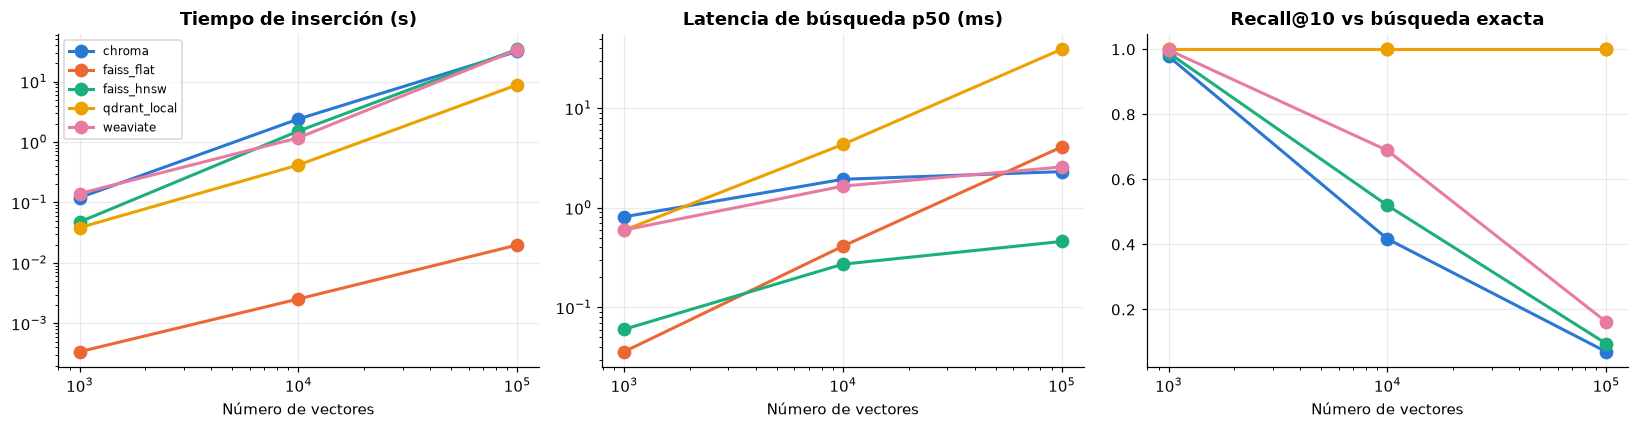

insercion_s                latencia_p50_ms                recall@10              
n                 1000   10000   100000          1000   10000   100000    1000   10000  100000
base                                                                                          
chroma             0.120  2.403  31.598           0.813  1.934   2.308     0.978  0.417  0.070
faiss_flat         0.000  0.003   0.020           0.036  0.412   4.084     1.000  1.000  1.000
faiss_hnsw         0.048  1.517  34.224           0.060  0.272   0.460     0.989  0.520  0.095
qdrant_local       0.038  0.417   8.822           0.596  4.326  39.007     1.000  1.000  1.000
weaviate           0.140  1.176  33.587           0.598  1.651   2.570     0.998  0.689  0.162

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, titulo in zip(axes, ["insercion_s", "latencia_p50_ms", "recall@10"],
                           ["Tiempo de inserción (s)", "Latencia de búsqueda p50 (ms)", "Recall@10 vs búsqueda exacta"]):
    for i, (nombre, d) in enumerate(df_escala.groupby("base", sort=False)):
        ax.plot(d["n"], d[col], marker="o", markersize=8, linewidth=2, color=PALETA[i % len(PALETA)], label=nombre)
    ax.set_xscale("log"); ax.set_xlabel("Número de vectores"); ax.set_title(titulo)
    if col != "recall@10":
        ax.set_yscale("log")
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()
display(df_escala.pivot(index="base", columns="n", values=["insercion_s", "latencia_p50_ms", "recall@10"]).round(3))

### 7.3 Comparación cualitativa (complementa las mediciones)

| Base | Costo | Escalabilidad | Facilidad de uso | Privacidad (datos en EcoMarket) |
|---|---|---|---|---|
| ChromaDB | Gratis (open source) | Un nodo; adecuada hasta millones de vectores | Muy alta: `pip install`, sin servidor | Sí |
| FAISS | Gratis (open source) | Muy alta en un nodo; sin distribución nativa | Media: hay que gestionar textos, metadatos y persistencia aparte | Sí |
| Qdrant | Gratis (open source); nube con capa gratuita | Alta: servidor con sharding y réplicas | Alta: mismo cliente de local a servidor | Sí (local / servidor propio) |
| Weaviate | Gratis (open source); nube de pago | Alta: cluster distribuido | Media: requiere servidor y esquema | Sí (servidor propio) |
| Pinecone | Capa gratuita limitada; pago por uso | Muy alta, administrada | Alta (sin operación), pero requiere red y API key | **No**: los datos se alojan en un tercero |

## 8. Resumen de resultados

Resumen automático de los experimentos. Los CSV completos quedan en `notebooks/resultados/`.

In [31]:
print("=" * 80)
print("Componentes no evaluados (limitaciones a documentar):")
for componente, motivo in (LIMITACIONES or {"ninguno": ""}).items():
    print(f"  - {componente}: {motivo}")
print("EXPERIMENTO 1 - Modelos de embeddings (mejor estrategia de cada uno)")
print(df_modelos[["mejor_estrategia", "mejor_mrr@5", "mejor_hit@1", "mejor_auc_fuera_alcance", "dim", "chunks_por_s", "latencia_query_ms"]].round(3).to_string())
print("\nEXPERIMENTO 1 - Estrategias de chunking (promedio modelos densos)")
print(df_chunking.round(3).to_string())
print("\nEXPERIMENTO 1 - MRR@5 por variante de pregunta")
print(por_variante.round(3).to_string())
print("\nEXPERIMENTO 1 - MRR@5 por fuente")
print(por_fuente.round(3).to_string())
print("\nEXPERIMENTO 1 - Umbral fuera de alcance")
print(df_umbrales.round(3).to_string())
print("\nEXPERIMENTO 2 - Estructurados: por registro vs aplanado")
print(df_estruct.round(3).to_string())
print("\nEXPERIMENTO 2 - Hibrido")
print(df_hibrido.round(3).to_string())
print("\nEXPERIMENTO 3 - Bases vectoriales (corpus real)")
print(df_vdb_real.round(3).to_string())
print("\nEXPERIMENTO 3 - Escala")
print(df_escala.round(3).to_string())
print("=" * 80)

Componentes no evaluados (limitaciones a documentar):
  - ninguno: 
EXPERIMENTO 1 - Modelos de embeddings (mejor estrategia de cada uno)
                   mejor_estrategia  mejor_mrr@5  mejor_hit@1  mejor_auc_fuera_alcance     dim  chunks_por_s  latencia_query_ms
modelo                                                                                                                         
nomic-v2-moe               parrafos        0.894        0.861                    0.994   768.0        88.825             10.686
openai-3-small            secciones        0.891        0.833                    0.996  1536.0        50.537            324.488
bge-m3                    semantico        0.863        0.778                    0.992  1024.0        91.876             13.848
e5-small                  secciones        0.848        0.778                    0.992   384.0       673.849              5.204
e5-base                    parrafos        0.824        0.750                    0.985   768.0 